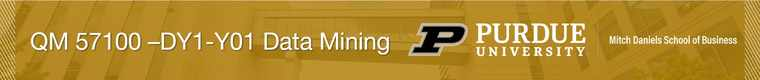

# QM 57100 — Data Mining | Module 3, Week 6 Lab
## **Random Forest:** train it, tune it, compare it with logistic regression, and meet gradient boosting

| | |
|---|---|
| **Format** | Google Colab notebook (Python) |
| **Companion to** | Lesson 6 video: Random Forest |
| **Datasets** | **Creditcard_appr.csv** — the same 689 U.S. Bank credit-card applications as in the Week 5 lab.<br> **Creditcard_appr_newclts.csv** — the same 20 new applicants, used in Section 6 and Section 7 |
| **Time** | about 100 min core + about 15 min optional |

### How this lab works
The video explained *why* one tree is unstable, how **bagging** and **random feature selection** build a forest, and how **boosting** differs. Here you **practice** on the Week 5 case: every step shows the code, the result, and how to read it on this dataset. Parts marked **🧭 Going deeper (optional)** can be skipped; nothing later depends on them.

| Symbol | Meaning |
|---|---|
| 📖 | One- or two-line reminder of the idea |
| 🔍 **What to notice** | How to read the result on this dataset |
| ✅ **Expected result** | A quick check that your output is right |
| 💡 ⚠️ 📌 | **Tip**, **Watch out**, **Heads up** boxes |

### The Sections
| Section | Question you answer | Main tools |
|---|---|---|
| 1 | Why is one tree not enough, and how does a forest fix it? | bootstrap samples, out-of-bag rows, a forest built by hand |
| 2 | How do I train a Random Forest and choose its settings? | `RandomForestClassifier`, the course configuration, one-lever-at-a-time sweeps, OOB score |
| 3 | How good is the forest on applicants it has never seen? | confusion matrix, Accuracy / Precision / Recall / F1, ROC, importance |
| 4 | What does an unregularized logistic regression give? | `LogisticRegression(C=np.inf)`, standardizing, coefficients |
| 5 | Logistic regression or Random Forest: which one do we select? | side-by-side metrics, ROC, noise in the comparison, explainability |
| 6 | What does the winner say about the 20 new applicants? | probabilities, decision rule, reveal |
| 7 | What is gradient boosting and does it beat both? | boosting figure, by-hand boosting, tuning, four-way comparison |

> 📌 **Heads up.** Loading data, the 80/20 split, 10-fold cross-validation, the confusion matrix, the four metrics and the ROC curve come from the Week 4 and Week 5 labs. They return here as tools with the **same seed, split and folds**, so Week 5 and Week 6 numbers can be compared directly. The new ideas are **bagging, random feature selection, out-of-bag scoring, model comparison and boosting**.

## Index

| Section | Steps |
|---|---|
| [Getting started — setup and data](#scrollTo=cell-002) | [Upload the dataset](#scrollTo=cell-004)<br>[The business case — U.S. Bank and the credit-card decision](#scrollTo=cell-006)<br>[Step 0.1 — Load the data](#scrollTo=cell-007)<br>[Step 0.2 — Split, folds and helper functions](#scrollTo=cell-010)<br>[Step 0.3 — The Week 5 benchmark](#scrollTo=cell-014) |
| [Section 1 — From one tree to a forest](#scrollTo=cell-017) | [Step 1.1 — Is a single tree really unstable?](#scrollTo=cell-018)<br>[Step 1.2 — Bootstrap samples and out-of-bag applicants](#scrollTo=cell-021)<br>[Step 1.3 — Build a forest by hand](#scrollTo=cell-024) |
| [Section 2 — Train the Random Forest](#scrollTo=cell-027) | [Step 2.1 — The configuration](#scrollTo=cell-028)<br>[Step 2.2 — Fit it and look inside](#scrollTo=cell-031)<br>[Step 2.3 — How good is it? Cross-validate](#scrollTo=cell-034)<br>[Step 2.4 — The out-of-bag score: validation for free](#scrollTo=cell-039) |
| [Section 3 — Evaluate the Random Forest on applicants it has never seen](#scrollTo=cell-042) | [Step 3.1 — Confusion matrix and the four metrics](#scrollTo=cell-043)<br>[Step 3.2 — Training vs test: does it overfit?](#scrollTo=cell-046)<br>[Step 3.3 — ROC curve against the Week 5 tree](#scrollTo=cell-049)<br>[Step 3.4 — Which predictors does the forest use?](#scrollTo=cell-052)<br>[🧭 Step 3.5 — Going deeper (optional): why random features help](#scrollTo=cell-055) |
| [Section 4 — Logistic regression, unregularized](#scrollTo=cell-058) | [Step 4.1 — Prepare the predictors](#scrollTo=cell-059)<br>[Step 4.2 — Fit it and read the coefficients](#scrollTo=cell-062)<br>[Step 4.3 — Evaluate on the test set](#scrollTo=cell-065) |
| [Section 5 — Logistic regression or Random Forest: which one do we select?](#scrollTo=cell-068) | [Step 5.1 — Side by side](#scrollTo=cell-069)<br>[Step 5.2 — ROC curves and the ten validation folds](#scrollTo=cell-072)<br>[Step 5.3 — Is the gap bigger than the noise?](#scrollTo=cell-075)<br>[Step 5.4 — The differences and the decision](#scrollTo=cell-078) |
| [Section 6 — Predict the 20 new applicants with the winner](#scrollTo=cell-081) | [Step 6.1 — Load the 20 new applicants](#scrollTo=cell-082)<br>[Step 6.2 — Predict the probability and apply the decision rule](#scrollTo=cell-085)<br>[Step 6.3 — Reveal what happened](#scrollTo=cell-088) |
| [Section 7 — Gradient boosting: learning from the errors](#scrollTo=cell-091) | [Step 7.1 — The idea in one figure](#scrollTo=cell-092)<br>[Step 7.2 — Boosting by hand on the credit data](#scrollTo=cell-095)<br>[Step 7.3 — Tune it: cross-validate the settings](#scrollTo=cell-098)<br>[Step 7.4 — Fit the optimal gradient boosting and evaluate it](#scrollTo=cell-103)<br>[Step 7.5 — Logistic regression vs Random Forest vs Gradient boosting](#scrollTo=cell-108)<br>[Step 7.6 — All four models on the 20 new applicants](#scrollTo=cell-116)<br>[Step 7.7 — Advantages and risks of boosting](#scrollTo=cell-119) |
| [Quick reference and practice](#scrollTo=cell-120) |  |
| [Wrap-up — Key ideas](#scrollTo=cell-123) |  |

*Tip: in Google Colab the Table of contents (left sidebar) also lists every Section. Plain Jupyter and VS Code do not follow these links.*

## Getting started — setup and data
📖 One style cell keeps every chart consistent. **scikit-learn** provides the forest (`RandomForestClassifier`), boosting (`GradientBoostingClassifier`), logistic regression and the metrics.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=FutureWarning)

# Fixed colors used in every chart of this lab
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
LIGHT_BLUE = "#9fc2ef"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

SEED = 42          # same seed as Week 5: same split, same folds, so the numbers are comparable
print("Setup done.")

Setup done.


### Upload the dataset
📖 Run the next cell. When the **Choose files** button appears, select **Creditcard_appr.csv** from your computer. If the file is already in the Colab session, nothing is asked.

In [2]:
FILE = "Creditcard_appr.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(FILE):
    if IN_COLAB:
        print("Select Creditcard_appr.csv from your computer...")
        files.upload()
    else:
        raise FileNotFoundError(f"Put {FILE} in the same folder as this notebook.")

assert os.path.exists(FILE), "Upload Creditcard_appr.csv (the file name must match exactly)."
print("File ready:", FILE)

Select Creditcard_appr.csv from your computer...


Saving Creditcard_appr.csv to Creditcard_appr.csv
File ready: Creditcard_appr.csv


### The business case — U.S. Bank and the credit-card decision


**The firm.** ***U.S. Bank*** issues credit cards to millions of customers. Its retail credit team reviews every new application and decides: **approve or deny**. In Week 5 you built a small decision tree for this decision and tested the Head of Retail Credit's belief that *"income and low debt decide who is a good credit risk."*

**The new question.** The Week 5 tree is easy to read, but it is **unstable**: change the training sample a little and the tree changes. The bank now asks you to try **ensembles** of trees and to check whether they are worth it, against a plain **logistic regression**, which is the classic scoring model in credit risk.

**The constraint has not changed.** The Equal Credit Opportunity Act requires a lender that denies credit to give the applicant specific reasons and forbids discrimination on characteristics such as sex or marital status. A model that scores a little better but cannot be explained may still be the wrong choice. You will weigh both.

**Questions to answer in this lab**
1. How is a Random Forest trained, and what does each of its settings do?
2. How good is it, compared with the single tree of Week 5 and with logistic regression?
3. Which of the two should the bank select, and on which criteria?
4. What would the selected model decide for the same 20 new applicants?
5. What is gradient boosting, and does it change the answer?

The columns are the same as in Week 5: the target `Approved` (1 = approved, 0 = denied) and ten predictors (`Gender`, `Age`, `Debt`, `Married`, `BankCustomer`, `YearsEmployed`, `Employed`, `CreditScore`, `DriversLicense`, `Income`). `Gender` and `Married` are legally protected characteristics: they stay in the file on purpose so that we can check whether the models use them.

### Step 0.1 — Load the data
📖 Same load as Week 5

In [3]:
raw = pd.read_csv(FILE)
df = raw.copy()                                   # never change the raw data
assert len(df) == 689, f"Expected 689 applications but found {len(df)} rows. Upload Creditcard_appr.csv."
assert set(df["Approved"].unique()) == {0, 1}, "Approved should only contain 0 (denied) and 1 (approved)."

TARGET = "Approved"                               # 1 = approved is the positive class
PRED = [c for c in df.columns if c != TARGET]

print(df.shape, "|", int(df.isna().sum().sum()), "missing |", int(df.duplicated().sum()), "duplicates")
print("Predictors:", PRED)
df.head()

(689, 11) | 0 missing | 0 duplicates
Predictors: ['Gender', 'Age', 'Debt', 'Married', 'BankCustomer', 'YearsEmployed', 'Employed', 'CreditScore', 'DriversLicense', 'Income']


,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,Employed,CreditScore,DriversLicense,Income,Approved
0,0,24.50,0.750,1,1,1.500,0,0,0,824,1
1,1,29.50,1.250,1,1,0.290,1,1,0,2803,0
2,1,21.50,0.625,1,1,0.250,0,0,0,0,0
3,0,36.75,1.000,1,1,5.000,0,0,1,4000,1
4,0,38.33,2.000,1,1,0.125,0,0,0,0,0


✅ **Expected result:** 689 rows and 11 columns, no missing values, no duplicates.

### Step 0.2 — Split, folds and helper functions
📖 The split and the folds are **identical to Week 5** (same seed, 80/20, stratified, 10 folds), so every number can be compared with that lab. The helper `score_model` cross-validates a model, fits it on the training set and stores its train and test scores in a scoreboard that we use until the end.

In [4]:
X = df[PRED]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)          # exactly the Week 5 split

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)   # exactly the Week 5 folds

summary = pd.DataFrame({"Applicants": [len(X_train), len(X_test)],
                        "Approved": [int(y_train.sum()), int(y_test.sum())],
                        "Approval rate": [y_train.mean(), y_test.mean()]}, index=["Training", "Test"])
summary["Approval rate"] = summary["Approval rate"].map("{:.1%}".format)
print(summary.to_string())

baseline_test = 1 - y_test.mean()                                  # always predict "denied"
print(f"\nBaseline accuracy (always 'denied') on the test set: {baseline_test:.3f}")
assert (len(X_train), len(X_test)) == (551, 138), "The split should match Week 5: 551 training and 138 test applicants."

          Applicants  Approved Approval rate
Training         551       228         41.4%
Test             138        57         41.3%

Baseline accuracy (always 'denied') on the test set: 0.587


In [5]:
THR = 0.5                                       # approve when P(approved) >= 0.5

def metrics_at(y_true, p, thr=0.5):
    """Confusion-matrix counts and the four metrics at a threshold (positive class = 1)."""
    pred = (np.asarray(p) >= thr).astype(int)
    TN, FP, FN, TP = confusion_matrix(y_true, pred).ravel()
    acc  = (TP + TN) / (TP + TN + FP + FN)
    prec = TP / (TP + FP) if TP + FP else 0.0
    rec  = TP / (TP + FN) if TP + FN else 0.0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"TN": int(TN), "FP": int(FP), "FN": int(FN), "TP": int(TP),
            "Accuracy": float(acc), "Precision": float(prec), "Recall": float(rec), "F1": float(f1)}

def cm_plot(cm, ax, title):
    ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("w_b", ["#ffffff", BLUE]), vmin=0, vmax=cm.max() * 1.25)
    labs = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labs[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Denied (0)", "Approved (1)"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Denied (0)", "Approved (1)"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title); ax.grid(False)

def diagnose(train_acc, test_acc, baseline, gap_limit=0.05, margin=0.05):
    """Rule-of-thumb diagnosis from Week 5 (not a statistical test)."""
    gap = train_acc - test_acc
    if gap > gap_limit:
        return "OVERFITTING"
    if train_acc < baseline + margin and test_acc < baseline + margin:
        return "UNDERFITTING"
    return "WELL FITTED"

board = {}        # the scoreboard: one entry per model, filled by score_model() and used from Section 4 on

def score_model(name, model, cols=None):
    """Cross-validate (same 10 folds), fit on the whole training set and score train and test."""
    cols = list(X.columns) if cols is None else list(cols)
    cv = cross_validate(model, X_train[cols], y_train, cv=skf, scoring=["accuracy", "roc_auc"], n_jobs=-1)
    t0 = time.perf_counter(); model.fit(X_train[cols], y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); p_te = model.predict_proba(X_test[cols])[:, 1]; score_s = time.perf_counter() - t0
    p_tr = model.predict_proba(X_train[cols])[:, 1]
    board[name] = dict(model=model, cols=cols, p_train=p_tr, p_test=p_te,
                       cv_auc=cv["test_roc_auc"], cv_acc=cv["test_accuracy"],
                       train=metrics_at(y_train, p_tr), test=metrics_at(y_test, p_te),
                       auc_train=roc_auc_score(y_train, p_tr), auc_test=roc_auc_score(y_test, p_te),
                       fit_s=fit_s, score_s=score_s)
    return board[name]

def cv_line(name):
    b = board[name]; se = b["cv_auc"].std(ddof=1) / np.sqrt(len(b["cv_auc"]))
    return f"{name}: CV AUC {b['cv_auc'].mean():.3f} (standard error {se:.3f}) | CV accuracy {b['cv_acc'].mean():.3f}"
print("Helper functions ready.")

Helper functions ready.


🔍 **What to notice:** 551 training and 138 test applicants, as in Week 5. The baseline "deny everybody" is right **58.7%** of the time on the test set, so every model must beat that.

### Step 0.3 — The Week 5 benchmark
📖 Our yardstick is the best-pruned tree of Week 5: depth 2, 4 leaves, chosen by cross-validation. We rebuild it here and put it on the scoreboard.

In [6]:
# The Week 5 model: the best-pruned tree (depth 2, 4 leaves) chosen with cross-validation
tree_ref = DecisionTreeClassifier(max_depth=2, random_state=SEED)
b = score_model("Single tree (Week 5)", tree_ref)

print(cv_line("Single tree (Week 5)"))
print(f"Training accuracy {b['train']['Accuracy']:.3f} | test accuracy {b['test']['Accuracy']:.3f} | test AUC {b['auc_test']:.3f}")
print(f"Leaves: {tree_ref.get_n_leaves()}")

Single tree (Week 5): CV AUC 0.790 (standard error 0.017) | CV accuracy 0.768
Training accuracy 0.793 | test accuracy 0.746 | test AUC 0.789
Leaves: 4


✅ **Expected result:** CV AUC 0.790, test accuracy 0.746 and test AUC 0.789, as in Week 5.

## Section 1 — From one tree to a forest
📖 A single tree has **high variance**: small changes in the training data give a different tree. Averaging many different trees keeps their strengths and cancels much of their noise. To get different trees from one dataset we **resample the rows** (bootstrap) and, in a Random Forest, also **limit the predictors** each split may consider.

### Step 1.1 — Is a single tree really unstable?
📖 We draw 10 bootstrap samples of the training set, grow one depth-3 tree on each, and compare the trees and their test AUC.

In [7]:
rng = np.random.default_rng(SEED)
n = len(X_train)

rows = []
for r in range(1, 11):
    idx = rng.integers(0, n, n)                                   # draw n applicants WITH replacement
    t = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
    root = f"{X.columns[t.tree_.feature[0]]} <= {t.tree_.threshold[0]:.2f}"
    used = sorted({X.columns[f] for f in t.tree_.feature if f >= 0})
    rows.append({"resample": r, "root question": root, "variables used": ", ".join(used),
                 "test AUC": roc_auc_score(y_test, t.predict_proba(X_test)[:, 1])})
unstable = pd.DataFrame(rows).set_index("resample")
pd.set_option("display.max_colwidth", None, "display.width", 200)
print(unstable.round(3).to_string())

print("\nDifferent root questions:", unstable["root question"].nunique(), "of 10")
print(f"Test AUC of these ten trees: from {unstable['test AUC'].min():.3f} to {unstable['test AUC'].max():.3f}")

                root question                                           variables used  test AUC
resample                                                                                        
1         CreditScore <= 2.50        Age, CreditScore, Employed, Income, YearsEmployed     0.778
2         CreditScore <= 2.50            Age, CreditScore, Debt, Income, YearsEmployed     0.816
3         CreditScore <= 2.50            Age, CreditScore, Debt, Income, YearsEmployed     0.767
4         CreditScore <= 2.50                  Age, CreditScore, Income, YearsEmployed     0.845
5         CreditScore <= 2.50                    Age, CreditScore, Debt, YearsEmployed     0.797
6         CreditScore <= 2.50            Age, CreditScore, Debt, Income, YearsEmployed     0.834
7         CreditScore <= 2.50            Age, CreditScore, Debt, Income, YearsEmployed     0.741
8         CreditScore <= 2.50  Age, CreditScore, Debt, Employed, Income, YearsEmployed     0.809
9         CreditScore <= 2.50 

🔍 **What to notice:**
- The **root question is the same** in all 10 trees (`CreditScore <= 2.50`): that predictor is so strong that every sample picks it first.
- Below the root the trees **differ**: each one uses 4 to 6 different predictors, and their **test AUC ranges from 0.741 to 0.845**. The same method on slightly different data gives a very different quality of model. That spread is the variance the forest will average away.

> 💡 **Tip.** Do not read the stable root as stability of the whole tree. Look at the variables used further down and at the test AUC.

### Step 1.2 — Bootstrap samples and out-of-bag applicants
📖 A **bootstrap sample** has the same size as the data and is drawn **with replacement**. Some applicants appear several times, others never. The ones never drawn are **out of bag (OOB)**: a free validation set for that tree.

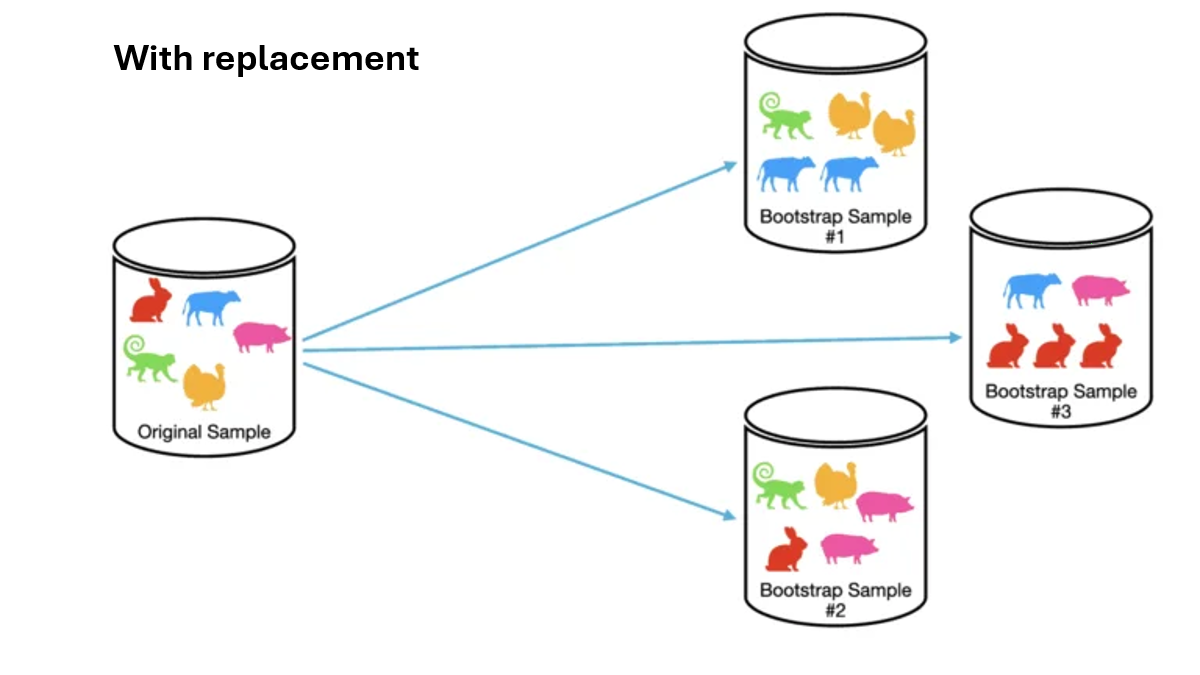

A bootstrap sample of 551 draws contains on average 63.2% of the distinct applicants
Theory: 1 - (1 - 1/n)^n = 63.2%   ->  about 36.8% of the applicants are 'out of bag'

One sample: 205 applicants never drawn (out of bag), 203 drawn once, 143 drawn two or more times (max 6)


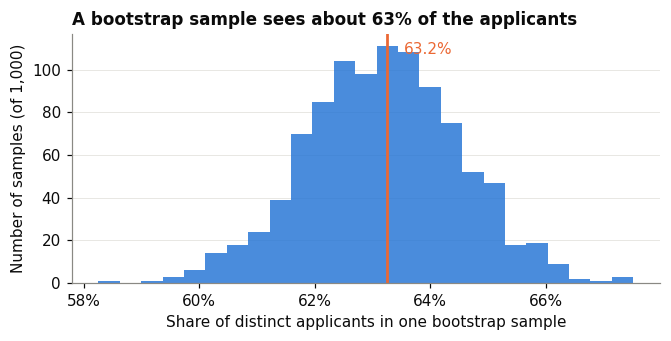

In [8]:
rng = np.random.default_rng(SEED)
n = len(X_train)

shares = np.array([len(np.unique(rng.integers(0, n, n))) / n for _ in range(1000)])   # share of distinct rows per sample
print(f"A bootstrap sample of {n} draws contains on average {shares.mean():.1%} of the distinct applicants")
print(f"Theory: 1 - (1 - 1/n)^n = {1 - (1 - 1 / n) ** n:.1%}   ->  about {1 - shares.mean():.1%} of the applicants are 'out of bag'")

one = rng.integers(0, n, n)
counts = np.bincount(one, minlength=n)
print(f"\nOne sample: {int((counts == 0).sum())} applicants never drawn (out of bag), "
      f"{int((counts == 1).sum())} drawn once, {int((counts >= 2).sum())} drawn two or more times (max {counts.max()})")

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.hist(shares, bins=25, color=BLUE, alpha=0.85)
ax.axvline(1 - (1 - 1 / n) ** n, color=ORANGE, lw=1.8)
ax.text(1 - (1 - 1 / n) ** n + 0.003, ax.get_ylim()[1] * 0.92, "63.2%", color=ORANGE, fontsize=10)
ax.set_xlabel("Share of distinct applicants in one bootstrap sample"); ax.set_ylabel("Number of samples (of 1,000)")
ax.set_title("A bootstrap sample sees about 63% of the applicants"); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

🔍 **What to notice:** a bootstrap sample contains on average **63.2%** of the distinct applicants, exactly what the formula 1 − (1 − 1/n)ⁿ predicts, so about **36.8% are out of bag** for each tree. In the single sample shown, 205 applicants were never drawn, 203 were drawn once and 143 were drawn two or more times (up to 6). Every tree is trained on a slightly different, slightly repeated version of the data.

### Step 1.3 — Build a forest by hand
📖 A Random Forest is a loop: bootstrap the rows, grow a **full tree** that looks at only `√p` randomly chosen predictors at every split (here √10 → 3), and repeat. The forest averages the trees' probabilities (or takes a majority vote).

100 trees | test AUC of ONE tree: mean 0.728 (from 0.629 to 0.814)
Forest by averaging probabilities: test AUC 0.904 | accuracy 0.826
Forest by majority vote          : accuracy 0.819

Applicant 306: 12 of 100 trees vote 'approve' -> forest probability 0.12 | actual decision: approved


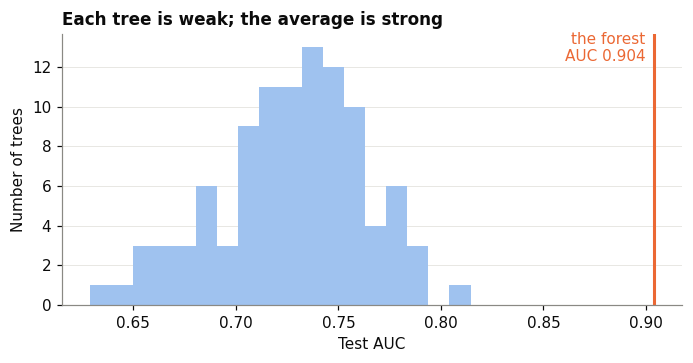

In [9]:
B = 100                                               # number of trees in our hand-made forest
rng = np.random.default_rng(SEED)
n = len(X_train)

hand_trees = []
for b in range(B):
    idx = rng.integers(0, n, n)                                       # layer 1: bootstrap sample of the rows
    t = DecisionTreeClassifier(max_features="sqrt",                  # layer 2: each split looks at 3 random predictors
                               random_state=int(rng.integers(1_000_000_000)))
    hand_trees.append(t.fit(X_train.iloc[idx], y_train.iloc[idx]))   # a full-grown tree: no pruning

P = np.array([t.predict_proba(X_test)[:, 1] for t in hand_trees])    # one row per tree, one column per test applicant
tree_auc = np.array([roc_auc_score(y_test, p) for p in P])

p_avg  = P.mean(axis=0)                                               # average of the probabilities
vote   = (P >= 0.5).mean(axis=0)                                      # share of trees that vote "approve"
print(f"{B} trees | test AUC of ONE tree: mean {tree_auc.mean():.3f} (from {tree_auc.min():.3f} to {tree_auc.max():.3f})")
print(f"Forest by averaging probabilities: test AUC {roc_auc_score(y_test, p_avg):.3f} | accuracy {accuracy_score(y_test, (p_avg >= 0.5)):.3f}")
print(f"Forest by majority vote          : accuracy {accuracy_score(y_test, (vote > 0.5)):.3f}")

first = X_test.index[0]
print(f"\nApplicant {first}: {int((P[:, 0] >= 0.5).sum())} of {B} trees vote 'approve' -> "
      f"forest probability {p_avg[0]:.2f} | actual decision: {'approved' if y_test.iloc[0] == 1 else 'denied'}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(tree_auc, bins=18, color=LIGHT_BLUE)
ax.axvline(roc_auc_score(y_test, p_avg), color=ORANGE, lw=2)
ax.text(roc_auc_score(y_test, p_avg) - 0.004, ax.get_ylim()[1] * 0.9, f"the forest\nAUC {roc_auc_score(y_test, p_avg):.3f}", color=ORANGE, ha="right", fontsize=10)
ax.set_xlabel("Test AUC"); ax.set_ylabel("Number of trees")
ax.set_title("Each tree is weak; the average is strong"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

🔍 **What to notice:**
- A **single** full-grown tree has a mean test AUC of only **0.728** (from 0.629 to 0.814), clearly worse than the pruned tree of Week 5 (0.789). Each tree alone is a weak model.
- Averaging 100 of them gives a test AUC of **0.904** and accuracy of **0.826**, better than every individual tree. Averaging probabilities (0.826) and majority vote (0.819) behave almost the same.
- The first test applicant, 306, shows how the vote works: only 12 of the 100 trees voted "approve", so the forest probability is 0.12. That applicant was in fact approved, a miss that the next Section will count.

> ⚠️ **Watch out.** This hand-made forest is a teaching tool. In the rest of the lab we use `RandomForestClassifier`, which does the same job faster and adds out-of-bag scoring and importance.

## Section 2 — Train the Random Forest
📖 Now the real tool. The configuration below is the one specified for this course; each line is one lever from the video.

### Step 2.1 — The configuration
📖 `n_estimators` = number of trees; `max_depth` and `min_samples_split` limit how far each tree grows; `max_features="sqrt"` is the √p rule for the predictors per split (the second layer of randomness); the rows of each tree come from a bootstrap sample of the same size as the training set.

In [10]:
rf_params = dict(
    n_estimators=50,          # how many trees
    max_depth=12,             # maximum levels of each tree
    min_samples_split=10,     # a node needs at least 10 applicants to be split
    min_samples_leaf=1,       # a leaf may hold a single applicant
    max_features="sqrt",      # each split looks at sqrt(10) -> 3 random predictors
    criterion="gini",         # same impurity measure as Week 5
    random_state=0,           # the seed of the forest (the data split keeps SEED = 42)
    class_weight=None,        # no re-weighting of approved / denied
)
rf_model = RandomForestClassifier(**rf_params)

p = len(PRED)
print(f"p = {p} predictors  ->  m = floor(sqrt(p)) = {int(np.sqrt(p))} predictors considered at each split")
print(f"Rows per tree: a bootstrap sample of n = {len(X_train)} applicants (drawn with replacement, about 63% distinct)")
print("\nThe configuration:"); print(pd.Series(rf_params).to_string())

p = 10 predictors  ->  m = floor(sqrt(p)) = 3 predictors considered at each split
Rows per tree: a bootstrap sample of n = 551 applicants (drawn with replacement, about 63% distinct)

The configuration:
n_estimators           50
max_depth              12
min_samples_split      10
min_samples_leaf        1
max_features         sqrt
criterion            gini
random_state            0
class_weight         None


🔍 **What to notice:** 50 trees, each allowed up to 12 levels, each node needs at least 10 applicants to be split, and each split chooses among **3 of the 10 predictors** drawn at random. Nothing here prunes the trees heavily: a forest wants **deep, low-bias trees** and gets its stability from the averaging, not from pruning.

> 📌 **Heads up.** Two seeds are in play: `SEED = 42` fixes the split and the folds (so Week 5 numbers repeat), and `random_state=0` inside the configuration fixes the forest itself.

### Step 2.2 — Fit it and look inside
📖 `fit` grows the 50 trees. A forest is a list of trees (`estimators_`), so we can inspect them like any tree.

Trees in the forest: 50
Depth of each tree : from 9 to 12 (mean 11.1), limit = 12
Leaves of each tree: from 39 to 53 (mean 45.8)   |   Week 5 tree: 4 leaves

Root question of the 50 trees, by predictor:
CreditScore      20
Income           11
Employed          7
YearsEmployed     7
Married           2
Debt              2
BankCustomer      1


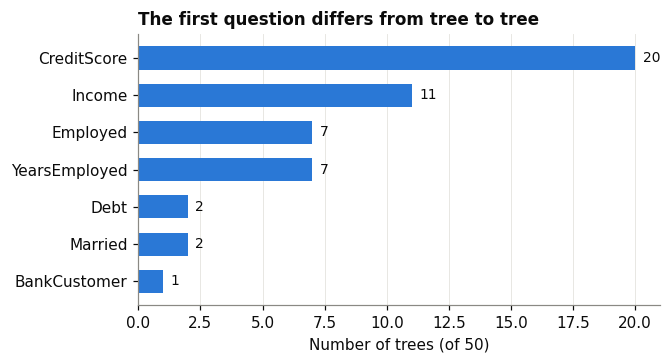

In [11]:
rf_model.fit(X_train, y_train)

depths = np.array([t.get_depth() for t in rf_model.estimators_])
leaves = np.array([t.get_n_leaves() for t in rf_model.estimators_])
print(f"Trees in the forest: {len(rf_model.estimators_)}")
print(f"Depth of each tree : from {depths.min()} to {depths.max()} (mean {depths.mean():.1f}), limit = {rf_params['max_depth']}")
print(f"Leaves of each tree: from {leaves.min()} to {leaves.max()} (mean {leaves.mean():.1f})   |   Week 5 tree: {tree_ref.get_n_leaves()} leaves")

# Which question does each tree ask first? Feature sampling makes the roots differ.
roots = pd.Series([X.columns[t.tree_.feature[0]] for t in rf_model.estimators_]).value_counts()
print("\nRoot question of the 50 trees, by predictor:"); print(roots.to_string())

fig, ax = plt.subplots(figsize=(6.2, 3.4))
s = roots.sort_values()
ax.barh(s.index, s.values, color=BLUE, height=0.62)
for yv, v in enumerate(s.values): ax.text(v + 0.3, yv, str(v), va="center", fontsize=9)
ax.set_xlabel("Number of trees (of 50)"); ax.set_title("The first question differs from tree to tree")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); plt.tight_layout(); plt.show()

🔍 **What to notice:**
- The trees are **big**: 39 to 53 leaves each (mean 45.8), against 4 leaves for the Week 5 tree. Each one is as overfitted as the 96-leaf tree of Week 5.
- The **first question differs from tree to tree**: `CreditScore` opens 20 of the 50 trees, but `Income`, `Employed`, `YearsEmployed`, `Married`, `Debt` and even `BankCustomer` open the others. That is the effect of looking at only 3 random predictors per split: trees that cannot all copy the strongest predictor become **less correlated**, and averaging works better on less correlated trees.

### Step 2.3 — How good is it? Cross-validate
📖 Same 10 folds as Week 5, scored with AUC. We also sweep **one lever at a time** while keeping the rest of the course configuration, to see which settings matter.

In [12]:
b = score_model("Random Forest", rf_model)           # cross-validation + fit + train/test scores
print(cv_line("Random Forest"))
print(cv_line("Single tree (Week 5)"))

def sweep(param, values):
    """Change ONE hyperparameter, keep the rest of the configuration, and cross-validate each value."""
    rows = []
    for v in values:
        r = cross_validate(RandomForestClassifier(**{**rf_params, param: v}), X_train, y_train, cv=skf,
                           scoring="roc_auc", return_train_score=True, n_jobs=-1)
        rows.append({"value": "None" if v is None else v, "train AUC": r["train_score"].mean(),
                     "CV AUC": r["test_score"].mean(), "se": r["test_score"].std(ddof=1) / np.sqrt(10)})
    return pd.DataFrame(rows)

grids = {"n_estimators": [5, 10, 25, 50, 100, 200, 500],
         "max_depth": [1, 2, 3, 4, 6, 8, 12, None],
         "min_samples_split": [2, 5, 10, 20, 40, 80],
         "max_features": [1, 2, "sqrt", 5, 7, 10]}
sw = {k: sweep(k, v) for k, v in grids.items()}
for k, t in sw.items():
    print(f"\n{k}  (course configuration = {rf_params[k]})")
    print(t.round(3).to_string(index=False))

Random Forest: CV AUC 0.881 (standard error 0.015) | CV accuracy 0.804
Single tree (Week 5): CV AUC 0.790 (standard error 0.017) | CV accuracy 0.768

n_estimators  (course configuration = 50)
 value  train AUC  CV AUC    se
     5      0.968   0.866 0.019
    10      0.977   0.873 0.016
    25      0.984   0.878 0.017
    50      0.985   0.881 0.015
   100      0.987   0.886 0.015
   200      0.988   0.890 0.014
   500      0.988   0.889 0.014

max_depth  (course configuration = 12)
value  train AUC  CV AUC    se
    1      0.864   0.863 0.012
    2      0.884   0.870 0.012
    3      0.911   0.878 0.014
    4      0.931   0.881 0.015
    6      0.964   0.881 0.014
    8      0.978   0.880 0.017
   12      0.985   0.881 0.015
 None      0.986   0.881 0.015

min_samples_split  (course configuration = 10)
 value  train AUC  CV AUC    se
     2      1.000   0.886 0.016
     5      0.998   0.878 0.016
    10      0.985   0.881 0.015
    20      0.963   0.887 0.015
    40      0.936   0.885

🔍 **What to notice:**
- The forest's **CV AUC is 0.881** (standard error 0.015), against **0.790** for the Week 5 tree: a gain of about 6 standard errors. Its CV accuracy is 0.804 against 0.768.
- **`n_estimators`:** 5 trees give 0.866, 50 give 0.881 and the curve flattens after about 100–200 trees (0.890 and 0.889 for 200 and 500). More trees never hurt; they only cost time.
- **`max_depth`:** CV AUC is 0.863 at depth 1, reaches 0.881 at depth 4 and stays at 0.881 up to no limit, while the **training** AUC keeps climbing from 0.864 to 0.986. Unlike a single tree, a forest does not get worse when its trees grow deep.
- **`min_samples_split`:** values from 2 to 40 all give 0.878–0.887, within one standard error of each other; only 80 starts to underfit (0.875).
- **`max_features`:** from 1 to 10 predictors per split the CV AUC stays between 0.879 and 0.886, again inside the noise of ±0.015.

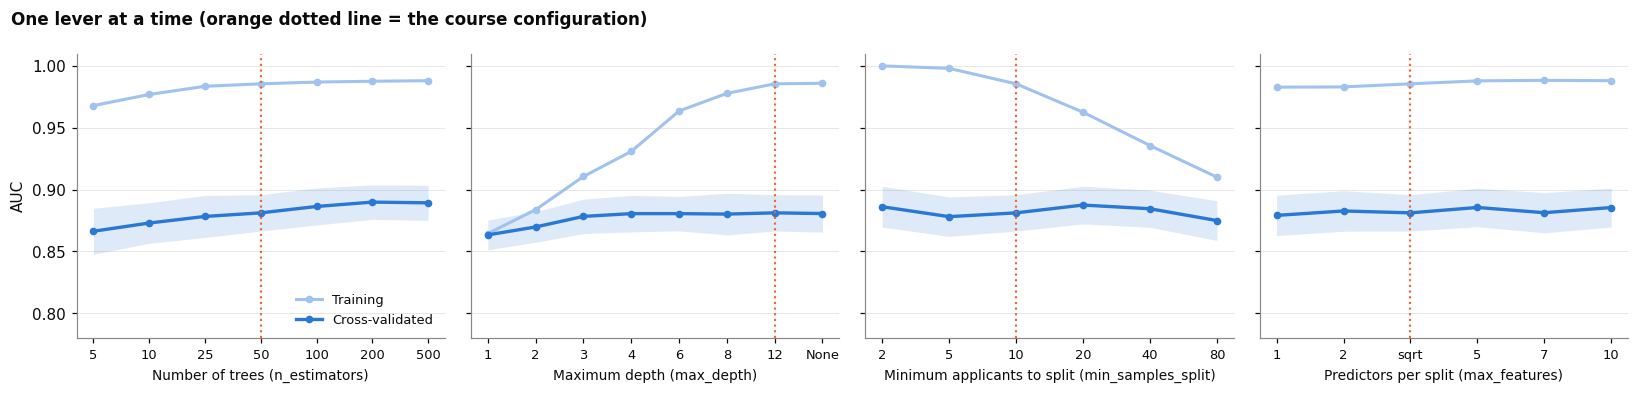

In [13]:
titles = {"n_estimators": "Number of trees (n_estimators)", "max_depth": "Maximum depth (max_depth)",
          "min_samples_split": "Minimum applicants to split (min_samples_split)", "max_features": "Predictors per split (max_features)"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (k, t) in zip(axes, sw.items()):
    xs = np.arange(len(t))
    ax.plot(xs, t["train AUC"], color=LIGHT_BLUE, lw=2, marker="o", ms=4, label="Training")
    ax.plot(xs, t["CV AUC"], color=BLUE, lw=2.2, marker="o", ms=4, label="Cross-validated")
    ax.fill_between(xs, t["CV AUC"] - t["se"], t["CV AUC"] + t["se"], color=BLUE, alpha=0.15, lw=0)
    cur = [str(v) for v in t["value"]].index(str(rf_params[k]))
    ax.axvline(cur, color=ORANGE, lw=1.4, ls=":")
    ax.set_xticks(xs); ax.set_xticklabels(t["value"].astype(str), fontsize=8.5); ax.set_xlabel(titles[k], fontsize=9)
    ax.grid(axis="x", visible=False); ax.set_ylim(0.78, 1.01)
axes[0].set_ylabel("AUC"); axes[0].legend(frameon=False, loc="lower right", fontsize=8.5)
fig.suptitle("One lever at a time (orange dotted line = the course configuration)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

🔍 **What to notice:** the blue cross-validated lines are almost flat across the whole range of every lever, and the shaded band (±1 standard error) covers them all. The course configuration (orange dotted line) sits **on the plateau**, so there is **no evidence that any other setting is better**; we keep it as our optimal Random Forest. The gap between the light-blue training line and the blue validation line shows the forest memorizes its training data and still generalizes: the validation score, not the training score, is the one to read.

> 💡 **Tip.** The only lever with a visible trend is the number of trees (+0.009 from 50 to 200). It is within the standard error, so we do not change the configuration, but 100–200 trees is a cheap, safe choice in practice.

### Step 2.4 — The out-of-bag score: validation for free
📖 Each applicant is out of bag for about 37% of the trees. Scoring it **only with those trees** gives an honest prediction without a validation set.

In [14]:
rf_oob = RandomForestClassifier(**{**rf_params, "oob_score": True}).fit(X_train, y_train)

oob_p = rf_oob.oob_decision_function_[:, 1]            # each applicant is scored ONLY by the trees that never saw it
ok = ~np.isnan(oob_p)
print(f"Applicants with an out-of-bag prediction: {int(ok.sum())} of {len(X_train)}")
print(f"Out-of-bag accuracy: {rf_oob.oob_score_:.3f}   |   out-of-bag AUC: {roc_auc_score(y_train[ok], oob_p[ok]):.3f}")
print(f"10-fold CV accuracy: {board['Random Forest']['cv_acc'].mean():.3f}   |   10-fold CV AUC: {board['Random Forest']['cv_auc'].mean():.3f}")
print(f"Test AUC (not used for anything yet): {board['Random Forest']['auc_test']:.3f}")

Applicants with an out-of-bag prediction: 551 of 551
Out-of-bag accuracy: 0.811   |   out-of-bag AUC: 0.880
10-fold CV accuracy: 0.804   |   10-fold CV AUC: 0.881
Test AUC (not used for anything yet): 0.897


🔍 **What to notice:** all 551 applicants have an out-of-bag prediction. The OOB accuracy (**0.811**) and OOB AUC (**0.880**) are almost identical to the 10-fold cross-validation (**0.804** and **0.881**), obtained from a single fit. The test AUC (0.897) is a little higher, which is within the noise of a 138-applicant test set.

> 💡 **Tip.** For big datasets, OOB is the cheap way to validate a forest: no folds to refit.

## Section 3 — Evaluate the Random Forest on applicants it has never seen
📖 Only now do we use the test set, once, with the optimal forest.

### Step 3.1 — Confusion matrix and the four metrics
📖 TP = approved and predicted approved; FP = denied but predicted approved (risky approval); FN = approved but predicted denied (lost customer); TN = denied and predicted denied. Threshold 0.5, as in Week 5.

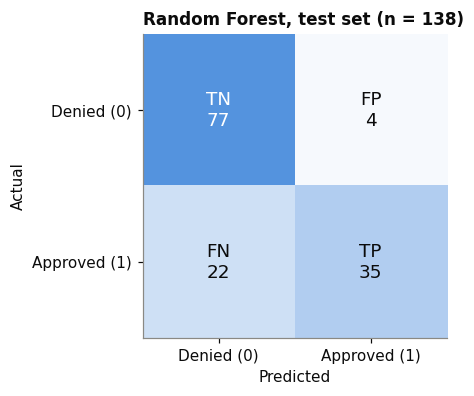

{'TN': 77, 'FP': 4, 'FN': 22, 'TP': 35, 'Accuracy': 0.812, 'Precision': 0.897, 'Recall': 0.614, 'F1': 0.729}
Baseline accuracy (always 'denied'): 0.587
Week 5 tree for reference: accuracy 0.746 | precision 0.893 | recall 0.439 | F1 0.588


In [15]:
b = board["Random Forest"]
cm_rf = confusion_matrix(y_test, (b["p_test"] >= THR).astype(int))
fig, ax = plt.subplots(figsize=(4.4, 3.7)); cm_plot(cm_rf, ax, f"Random Forest, test set (n = {len(y_test)})")
plt.tight_layout(); plt.show()

print({k: (int(v) if k in ("TN", "FP", "FN", "TP") else round(v, 3)) for k, v in b["test"].items()})
print(f"Baseline accuracy (always 'denied'): {baseline_test:.3f}")
w5 = board["Single tree (Week 5)"]["test"]
print(f"Week 5 tree for reference: accuracy {w5['Accuracy']:.3f} | precision {w5['Precision']:.3f} | recall {w5['Recall']:.3f} | F1 {w5['F1']:.3f}")

🔍 **What to notice:** of 138 test applicants the forest decided **112 correctly** (accuracy **0.812**, baseline 0.587). It made **4 risky approvals** and **22 missed approvals**. Precision is **0.897** (almost 9 of 10 approvals are right) and recall is **0.614**; F1 is **0.729**. Against the Week 5 tree (accuracy 0.746, recall 0.439, F1 0.588) the forest finds many more of the good applicants at nearly the same precision.

### Step 3.2 — Training vs test: does it overfit?
📖 The Week 5 rule of thumb: a training accuracy more than 5 points above the test accuracy suggests overfitting.

In [16]:
base_train = 1 - y_train.mean()
tree_full = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)         # the Week 5 full-grown tree
p_full_tr, p_full_te = tree_full.predict_proba(X_train)[:, 1], tree_full.predict_proba(X_test)[:, 1]

models_diag = {
    "Full-grown tree (Week 5)": (metrics_at(y_train, p_full_tr)["Accuracy"], metrics_at(y_test, p_full_te)["Accuracy"],
                                 roc_auc_score(y_train, p_full_tr), roc_auc_score(y_test, p_full_te)),
    "Single tree (Week 5)":     (board["Single tree (Week 5)"]["train"]["Accuracy"], board["Single tree (Week 5)"]["test"]["Accuracy"],
                                 board["Single tree (Week 5)"]["auc_train"], board["Single tree (Week 5)"]["auc_test"]),
    "Random Forest":            (board["Random Forest"]["train"]["Accuracy"], board["Random Forest"]["test"]["Accuracy"],
                                 board["Random Forest"]["auc_train"], board["Random Forest"]["auc_test"]),
}
rows = []
for name, (a_tr, a_te, u_tr, u_te) in models_diag.items():
    rows.append({"Model": name, "Train acc.": a_tr, "Test acc.": a_te, "Gap": a_tr - a_te,
                 "Train AUC": u_tr, "Test AUC": u_te, "Diagnosis": diagnose(a_tr, a_te, base_train)})
diag_tbl = pd.DataFrame(rows).set_index("Model")
print(diag_tbl.round(3).to_string())

                          Train acc.  Test acc.    Gap  Train AUC  Test AUC    Diagnosis
Model                                                                                   
Full-grown tree (Week 5)       1.000      0.710  0.290      1.000     0.696  OVERFITTING
Single tree (Week 5)           0.793      0.746  0.047      0.823     0.789  WELL FITTED
Random Forest                  0.933      0.812  0.121      0.987     0.897  OVERFITTING


🔍 **What to notice:**
- The rule flags the forest as **OVERFITTING** (train 0.933, test 0.812, gap 0.121), but look at the numbers around it: its test accuracy (0.812) and test AUC (**0.897**) are **higher** than those of the "well fitted" Week 5 tree (0.746 and 0.789).
- A forest's training score is inflated by construction: every applicant is in the bag for about 63% of the trees and each tree is deep enough to memorize it. So the gap rule is too harsh for forests. For a forest, trust the **out-of-bag score, the cross-validation and the test score**, which all agree here (AUC 0.880, 0.881, 0.897).

> ⚠️ **Watch out.** A rule of thumb is not a verdict. Always read the gap together with the test performance.

### Step 3.3 — ROC curve against the Week 5 tree
📖 The ROC curve shows recall against the false-alarm rate for every threshold; AUC is the area under it.

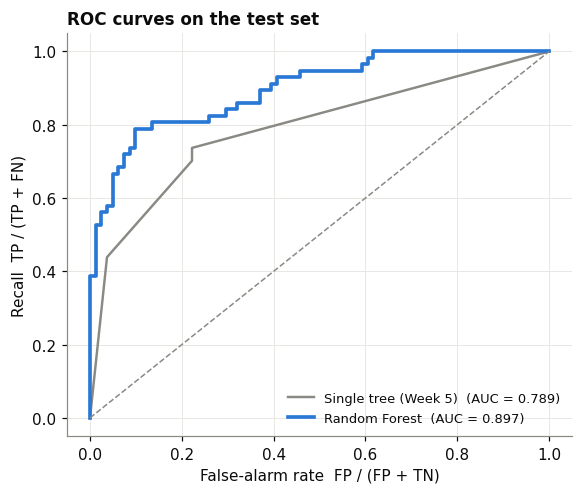

In [17]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
for name, col, lw in [("Single tree (Week 5)", GRAY, 1.6), ("Random Forest", BLUE, 2.4)]:
    fpr, tpr, _ = roc_curve(y_test, board[name]["p_test"])
    ax.plot(fpr, tpr, color=col, lw=lw, label=f"{name}  (AUC = {board[name]['auc_test']:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
ax.set_xlabel("False-alarm rate  FP / (FP + TN)"); ax.set_ylabel("Recall  TP / (TP + FN)")
ax.set_title("ROC curves on the test set"); ax.legend(frameon=False, loc="lower right", fontsize=8.5); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

🔍 **What to notice:** the forest's blue curve lies above the gray tree curve over almost the whole range, and its curve has many more corners because it averages 50 trees and so outputs many different probabilities. AUC rises from **0.789** to **0.897**.

### Step 3.4 — Which predictors does the forest use?
📖 **Gini importance** adds up the impurity each predictor removes in all trees (sums to 1); it is quick but can favor predictors with many distinct values. **Permutation importance** shuffles one predictor in the test set and measures the AUC lost, which is more reliable but noisier.

                Gini importance (forest)  Permutation (test AUC drop)  Single tree (Week 5)
CreditScore                        0.272                        0.059                 0.823
Income                             0.190                        0.058                 0.124
YearsEmployed                      0.169                        0.070                 0.000
Debt                               0.133                        0.037                 0.000
Age                                0.112                        0.002                 0.053
Employed                           0.077                        0.015                 0.000
BankCustomer                       0.014                       -0.001                 0.000
DriversLicense                     0.013                       -0.002                 0.000
Gender                             0.010                        0.005                 0.000
Married                            0.009                       -0.004           

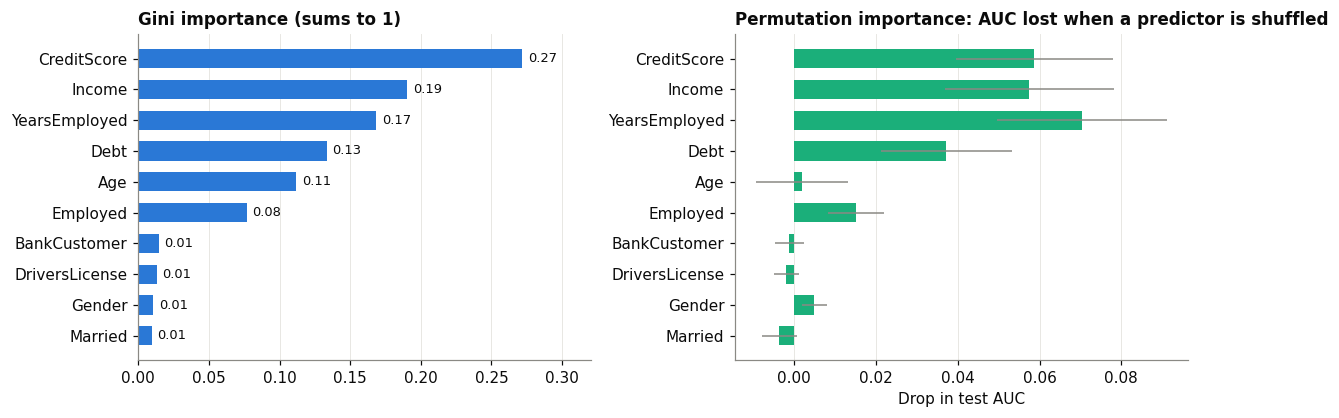


Protected characteristics (Gender, Married) in the forest:
         Gini importance (forest)  Permutation (test AUC drop)
Gender                      0.010                        0.005
Married                     0.009                       -0.004
Married vs BankCustomer (identical columns): Gini importance 0.009 and 0.014


In [18]:
rf = board["Random Forest"]["model"]
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)

imp = pd.DataFrame({"Gini importance (forest)": rf.feature_importances_,
                    "Permutation (test AUC drop)": perm.importances_mean,
                    "Single tree (Week 5)": tree_ref.feature_importances_}, index=X.columns)
print(imp.sort_values("Gini importance (forest)", ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
s = imp["Gini importance (forest)"].sort_values()
axes[0].barh(s.index, s.values, color=BLUE, height=0.62)
for yv, v in enumerate(s.values): axes[0].text(v + 0.004, yv, f"{v:.2f}", va="center", fontsize=8.5)
axes[0].set_title("Gini importance (sums to 1)"); axes[0].set_xlim(0, s.max() * 1.18)
q = imp["Permutation (test AUC drop)"].reindex(s.index)
sd = pd.Series(perm.importances_std, index=X.columns).reindex(s.index)
axes[1].barh(q.index, q.values, xerr=sd.values, color=AQUA, height=0.62, error_kw=dict(ecolor=GRAY, lw=1))
axes[1].set_title("Permutation importance: AUC lost when a predictor is shuffled"); axes[1].set_xlabel("Drop in test AUC")
for ax in axes: ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

print("\nProtected characteristics (Gender, Married) in the forest:")
print(imp.loc[["Gender", "Married"], ["Gini importance (forest)", "Permutation (test AUC drop)"]].round(3).to_string())
print(f"Married vs BankCustomer (identical columns): Gini importance {imp.loc['Married', 'Gini importance (forest)']:.3f} and {imp.loc['BankCustomer', 'Gini importance (forest)']:.3f}")

🔍 **What to notice:**
- The forest **spreads** its importance: `CreditScore` 0.27, `Income` 0.19, `YearsEmployed` 0.17, `Debt` 0.13, `Age` 0.11. The Week 5 tree put 82% on `CreditScore` alone.
- The permutation view agrees that `CreditScore`, `Income`, `YearsEmployed` and `Debt` matter (AUC losses of 0.059, 0.058, 0.070 and 0.037). `Age` shows almost no loss (0.002) in spite of a Gini importance of 0.11, an example of why two importance measures are better than one.
- **Compliance check:** `Gender` and `Married` get a small Gini importance (0.010 and 0.009) and a permutation importance near zero (0.005 and −0.004, inside the noise). They are not driving the decisions, but the forest does **see** them, whereas the pruned tree did not use them at all.
- `Married` and `BankCustomer` are the identical column, so the forest splits their importance arbitrarily between them (0.009 and 0.014): never read these two separately.

### 🧭 Step 3.5 — Going deeper (optional): why random features help
📖 With variance ≈ ρσ² + (1 − ρ)σ²/B, adding trees only removes the second term; to lower the first you need **less correlated trees**. We compare **bagging** (every split sees all 10 predictors) with the Random Forest (3 per split), scored by out-of-bag AUC.

In [ ]:
def mean_tree_corr(forest):
    """Average correlation between the test-set probabilities of every pair of trees."""
    Pm = np.array([t.predict_proba(X_test.to_numpy())[:, 1] for t in forest.estimators_])
    Cm = np.corrcoef(Pm)
    return Cm[np.triu_indices_from(Cm, k=1)].mean()

def oob_auc(forest):
    pp = forest.oob_decision_function_[:, 1]; ok = ~np.isnan(pp)
    return roc_auc_score(y_train[ok], pp[ok])

curve = []
for n_trees in [30, 50, 100, 200, 300]:
    for label, mf in [("Bagging (all 10 predictors per split)", None), ("Random Forest (3 predictors per split)", "sqrt")]:
        f = RandomForestClassifier(**{**rf_params, "n_estimators": n_trees, "max_features": mf, "oob_score": True}).fit(X_train, y_train)
        curve.append({"trees": n_trees, "model": label, "OOB AUC": oob_auc(f)})
curve = pd.DataFrame(curve).pivot(index="trees", columns="model", values="OOB AUC")
print(curve.round(3).to_string())

bag  = RandomForestClassifier(**{**rf_params, "max_features": None}).fit(X_train, y_train)   # bagging: no feature sampling
print(f"\nAverage correlation between two trees (50 trees): bagging {mean_tree_corr(bag):.3f} | random forest {mean_tree_corr(rf_model):.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for col, color in zip(curve.columns, [GRAY, BLUE]):
    ax.plot(curve.index, curve[col], marker="o", ms=4, lw=2, color=color, label=col)
ax.set_xscale("log"); ax.set_xticks([30, 50, 100, 200, 300]); ax.set_xticklabels([30, 50, 100, 200, 300])
ax.set_xlabel("Number of trees"); ax.set_ylabel("Out-of-bag AUC"); ax.set_title("More trees help; random features help more")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

🔍 **What to notice:** the average correlation between two trees drops from **0.612** (bagging) to **0.554** (forest). The out-of-bag AUC is slightly higher for the forest at every size (for example 0.880 against 0.868 with 50 trees) and both curves flatten after about 100–200 trees. The effect is small on this dataset, which has a few dominant predictors and only ten in total; it matters more with many predictors.

> ⚠️ **Watch out.** The 10-fold CV of Practice question 3 may rank the two the other way round by a hair. Differences of 0.005 are noise: judge by the pattern, not by one number.

## Section 4 — Logistic regression, unregularized
📖 Logistic regression models the **log-odds** of approval as a straight-line combination of the predictors. "Unregularized" means no penalty on the coefficients: `C=np.inf` (C is the inverse of the penalty strength). It needs **standardized** predictors to be well behaved, unlike trees.

### Step 4.1 — Prepare the predictors
📖 `Married` and `BankCustomer` are identical (Week 5). In a regression, identical columns make the coefficients undetermined, so we keep only one. The scaler goes **inside a pipeline**, so it learns its means and standard deviations from training data only.

In [19]:
print("Married equals BankCustomer for every applicant:", bool((df["Married"] == df["BankCustomer"]).all()))

LR_COLS = [c for c in PRED if c != "BankCustomer"]       # drop one of the two identical columns
print("Predictors for logistic regression:", LR_COLS)

def make_lr():
    """Logistic regression WITHOUT regularization, on standardized predictors.
    C is the inverse of the penalty strength: C = infinity means no penalty."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))

Married equals BankCustomer for every applicant: True
Predictors for logistic regression: ['Gender', 'Age', 'Debt', 'Married', 'YearsEmployed', 'Employed', 'CreditScore', 'DriversLicense', 'Income']


✅ **Expected result:** `True`, and 9 predictors.

### Step 4.2 — Fit it and read the coefficients
📖 Each coefficient is the change in log-odds for **one standard deviation** of that predictor; its exponential is the **odds ratio**.

Intercept: -0.007
                coefficient  odds ratio (per 1 SD)
Income                2.738                 15.455
CreditScore           1.523                  4.587
YearsEmployed         0.927                  2.527
Employed              0.354                  1.425
Age                   0.337                  1.401
Married               0.196                  1.217
DriversLicense       -0.043                  0.958
Gender               -0.092                  0.912
Debt                 -0.905                  0.404


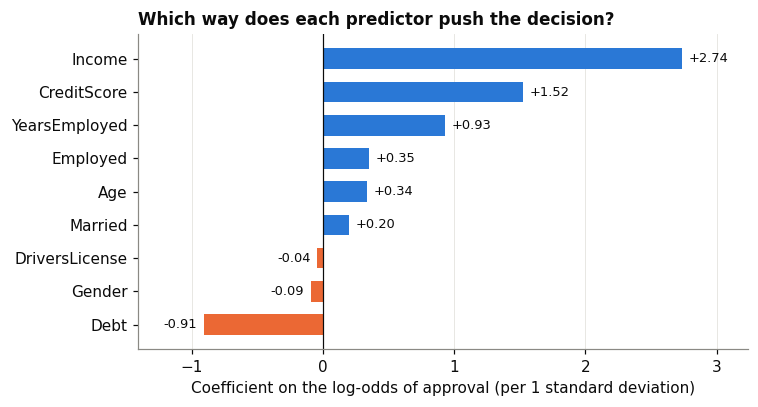

In [20]:
lr_model = make_lr()
b = score_model("Logistic regression", lr_model, cols=LR_COLS)

coef = pd.Series(lr_model[-1].coef_[0], index=LR_COLS)            # per 1 standard deviation of each predictor
coef_tbl = pd.DataFrame({"coefficient": coef, "odds ratio (per 1 SD)": np.exp(coef)}).sort_values("coefficient", ascending=False)
print(f"Intercept: {lr_model[-1].intercept_[0]:.3f}")
print(coef_tbl.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.0, 3.8))
s = coef_tbl["coefficient"].sort_values()
ax.barh(s.index, s.values, color=[ORANGE if v < 0 else BLUE for v in s.values], height=0.62)
for yv, v in enumerate(s.values): ax.text(v + (0.05 if v >= 0 else -0.05), yv, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5)
ax.axvline(0, color=INK, lw=0.8); ax.set_xlim(s.min() - 0.5, s.max() + 0.5)
ax.set_xlabel("Coefficient on the log-odds of approval (per 1 standard deviation)")
ax.set_title("Which way does each predictor push the decision?"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

🔍 **What to notice:**
- Directions make business sense: `Income`, `CreditScore` and `YearsEmployed` push toward approval, and `Debt` pushes toward denial (odds ratio 0.40 per standard deviation). `Gender` (−0.09) and `DriversLicense` (−0.04) are near zero.
- **Careful with size:** `Income` shows a coefficient of 2.74 (odds × 15.5 per standard deviation), but income is very skewed, so a "standard deviation" is a huge jump. And `Employed` and `CreditScore` carry overlapping information, so do not over-read the signs of correlated predictors.
- `Married` has a small positive coefficient (+0.20). This is a protected characteristic, and a regression gives you a number to inspect and, if the bank decides, to remove. The model is **transparent about what it uses**.

### Step 4.3 — Evaluate on the test set
📖 Same metrics and the same threshold as for the forest.

Logistic regression: CV AUC 0.876 (standard error 0.019) | CV accuracy 0.807
{'TN': 77, 'FP': 4, 'FN': 20, 'TP': 37, 'Accuracy': 0.826, 'Precision': 0.902, 'Recall': 0.649, 'F1': 0.755}
Training accuracy 0.820 | test accuracy 0.826 | gap -0.006 -> WELL FITTED


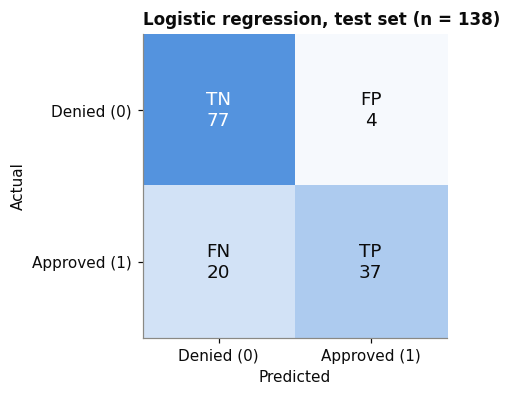

In [21]:
print(cv_line("Logistic regression"))
b = board["Logistic regression"]
print({k: (int(v) if k in ("TN", "FP", "FN", "TP") else round(v, 3)) for k, v in b["test"].items()})
print(f"Training accuracy {b['train']['Accuracy']:.3f} | test accuracy {b['test']['Accuracy']:.3f} | gap {b['train']['Accuracy'] - b['test']['Accuracy']:.3f} "
      f"-> {diagnose(b['train']['Accuracy'], b['test']['Accuracy'], base_train)}")

cm_lr = confusion_matrix(y_test, (b["p_test"] >= THR).astype(int))
fig, ax = plt.subplots(figsize=(4.4, 3.7)); cm_plot(cm_lr, ax, f"Logistic regression, test set (n = {len(y_test)})")
plt.tight_layout(); plt.show()

🔍 **What to notice:** CV AUC **0.876** (standard error 0.019). On the test set the model decided **114 of 138** correctly (accuracy **0.826**), with precision **0.902**, recall **0.649** and F1 **0.755**. The training accuracy is 0.820, so the gap is **−0.006**: no overfitting, as expected from a model with only 10 parameters.

## Section 5 — Logistic regression or Random Forest: which one do we select?
📖 Choosing a model means choosing **criteria first**: predictive quality (and how sure we are of it), stability, explainability under the law, and cost to run and maintain.

### Step 5.1 — Side by side
📖 One table, same test set, same threshold.

In [22]:
names = ["Logistic regression", "Random Forest"]
rows = []
for nme in names:
    b = board[nme]
    rows.append({"Model": nme, "CV AUC": b["cv_auc"].mean(), "Accuracy": b["test"]["Accuracy"], "Precision": b["test"]["Precision"],
                 "Recall": b["test"]["Recall"], "F1": b["test"]["F1"], "Test AUC": b["auc_test"],
                 "Train acc. - test acc.": b["train"]["Accuracy"] - b["test"]["Accuracy"]})
cmp2 = pd.DataFrame(rows).set_index("Model")
print("Test-set metrics at threshold 0.5 (CV AUC comes from the training set)")
print(cmp2.round(3).to_string())
print(f"\nBaseline accuracy (always 'denied'): {baseline_test:.3f}")

Test-set metrics at threshold 0.5 (CV AUC comes from the training set)
                     CV AUC  Accuracy  Precision  Recall     F1  Test AUC  Train acc. - test acc.
Model                                                                                            
Logistic regression   0.876     0.826      0.902   0.649  0.755     0.897                  -0.006
Random Forest         0.881     0.812      0.897   0.614  0.729     0.897                   0.121

Baseline accuracy (always 'denied'): 0.587


🔍 **What to notice:** the two models are almost tied. The logistic regression is slightly ahead on accuracy (0.826 against 0.812, a difference of **2 applicants** out of 138), precision (0.902 against 0.897), recall (0.649 against 0.614) and F1 (0.755 against 0.729). The Random Forest is slightly ahead on CV AUC (0.881 against 0.876). The **test AUC is identical (0.897)**. Only the gap column differs: −0.006 for logistic regression and 0.121 for the forest.

### Step 5.2 — ROC curves and the ten validation folds
📖 Left: both ROC curves on the test set. Right: the ten validation AUCs of each model, over the same folds.

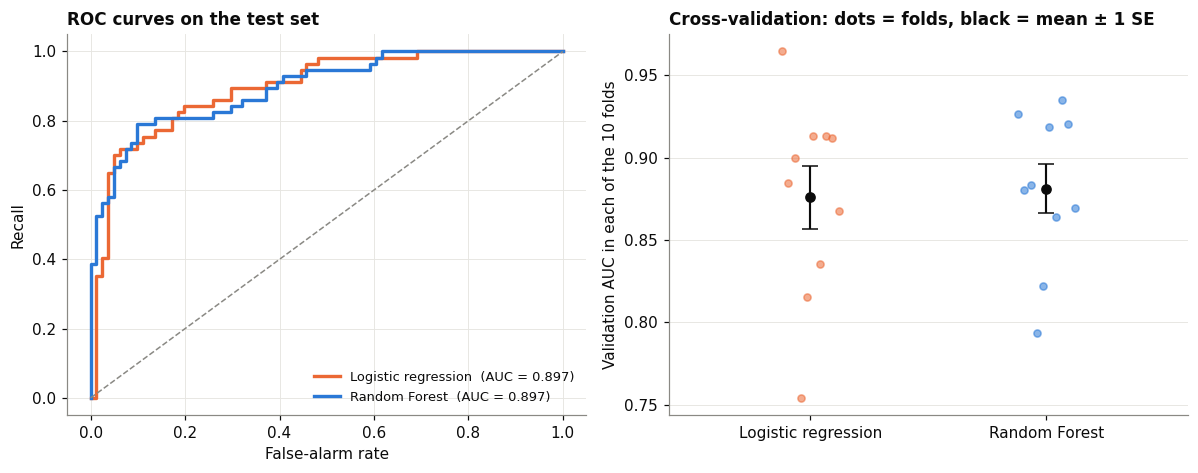

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for name, col in [("Logistic regression", ORANGE), ("Random Forest", BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, board[name]["p_test"])
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f"{name}  (AUC = {board[name]['auc_test']:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
ax.set_xlabel("False-alarm rate"); ax.set_ylabel("Recall"); ax.set_title("ROC curves on the test set")
ax.legend(frameon=False, loc="lower right", fontsize=8.5); ax.grid(axis="x", visible=True)

ax = axes[1]
for k, (name, col) in enumerate([("Logistic regression", ORANGE), ("Random Forest", BLUE)]):
    v = board[name]["cv_auc"]
    ax.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, color=col, alpha=0.55, s=22)
    ax.errorbar(k, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color=INK, ms=6, capsize=5, lw=1.4)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Logistic regression", "Random Forest"]); ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Validation AUC in each of the 10 folds"); ax.set_title("Cross-validation: dots = folds, black = mean ± 1 SE")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

🔍 **What to notice:** the two ROC curves cross each other several times and are on top of each other for most of the range. In the right panel the two clouds of fold scores overlap almost completely and the means (black dots) are inside each other's error bars.

### Step 5.3 — Is the gap bigger than the noise?
📖 With 138 test applicants, any difference of one or two points can be luck. We measure the noise in two ways: the **paired difference over the same folds**, and a **bootstrap of the test set** (redraw 138 applicants 1,000 times and recompute the AUCs).

In [24]:
# Paired difference over the SAME 10 folds
d_cv = board["Random Forest"]["cv_auc"] - board["Logistic regression"]["cv_auc"]
d_mean, d_se = d_cv.mean(), d_cv.std(ddof=1) / np.sqrt(len(d_cv))
print(f"CV AUC, Random Forest minus Logistic regression: {d_mean:+.3f}  (standard error {d_se:.3f}, from {d_mean - 2 * d_se:+.3f} to {d_mean + 2 * d_se:+.3f} at about 95%)")

# How much could the TEST AUC move if we had drawn another 138 applicants? Bootstrap the test set.
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy(); p_rf, p_lr = board["Random Forest"]["p_test"], board["Logistic regression"]["p_test"]
auc_rf_b, auc_lr_b = [], []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max(): continue
    auc_rf_b.append(roc_auc_score(yt[i], p_rf[i])); auc_lr_b.append(roc_auc_score(yt[i], p_lr[i]))
auc_rf_b, auc_lr_b = np.array(auc_rf_b), np.array(auc_lr_b)
lo, hi = np.percentile(auc_rf_b - auc_lr_b, [2.5, 97.5])
print(f"Test AUC, Random Forest: {board['Random Forest']['auc_test']:.3f}  (95% range {np.percentile(auc_rf_b, 2.5):.3f} to {np.percentile(auc_rf_b, 97.5):.3f})")
print(f"Test AUC, Logistic regression: {board['Logistic regression']['auc_test']:.3f}  (95% range {np.percentile(auc_lr_b, 2.5):.3f} to {np.percentile(auc_lr_b, 97.5):.3f})")
print(f"Difference in test AUC (RF minus LR): 95% range from {lo:+.3f} to {hi:+.3f}")

CV AUC, Random Forest minus Logistic regression: +0.005  (standard error 0.007, from -0.009 to +0.019 at about 95%)
Test AUC, Random Forest: 0.897  (95% range 0.841 to 0.947)
Test AUC, Logistic regression: 0.897  (95% range 0.840 to 0.948)
Difference in test AUC (RF minus LR): 95% range from -0.038 to +0.041


🔍 **What to notice:**
- Over the 10 folds the forest is ahead by **+0.005** AUC with a standard error of **0.007**: less than one standard error, so **no real difference**.
- The test AUC of each model could easily move by about ±0.05 with another sample of 138 applicants (95% ranges 0.841–0.947 and 0.840–0.948), and the **difference** between the two could fall anywhere from −0.038 to +0.041. The data cannot separate these two models on accuracy.

### Step 5.4 — The differences and the decision
📖 When performance is a tie, the other criteria decide. We encode the rule in a function so it can be reused: *if the paired CV difference is smaller than one standard error, keep the simpler, explainable model.*

In [25]:
def pick_winner(a, b, board=board):
    """Selection rule: compare the cross-validated AUC of two models over the same folds.
    If the paired difference is smaller than 1 standard error, call it a tie and take the simpler model (a)."""
    d = board[b]["cv_auc"] - board[a]["cv_auc"]
    mean, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    if abs(mean) < se:
        return a, f"{b} minus {a} = {mean:+.3f} CV AUC, smaller than 1 SE ({se:.3f}): a tie, so we keep the simpler, explainable model"
    return (b if mean > 0 else a), f"{b} minus {a} = {mean:+.3f} CV AUC, larger than 1 SE ({se:.3f}): the higher model is ahead in cross-validation"

winner_name, why = pick_winner("Logistic regression", "Random Forest")
print("Rule:", why)
print("Winner:", winner_name)

Rule: Random Forest minus Logistic regression = +0.005 CV AUC, smaller than 1 SE (0.007): a tie, so we keep the simpler, explainable model
Winner: Logistic regression


| Criterion | Logistic regression | Random Forest |
|---|---|---|
| **Predictive quality** (CV AUC, test AUC, F1) | 0.876, 0.897, 0.755 | 0.881, 0.897, 0.729: a **statistical tie** |
| **Overfitting gap** (train − test accuracy) | −0.006 | 0.121 (inflated by construction, but an extra worry to monitor) |
| **Form of the model** | one equation, 10 numbers | 50 trees with about 46 leaves each (about 2,300 rules) |
| **Explainability / ECOA** | each decision traced to named predictors and their effect | no short reason for a single decision; needs extra tools |
| **Handling of the data** | needs standardizing, assumes straight-line effects on the log-odds | no standardizing, captures interactions and thresholds without being told |
| **Speed and upkeep** | trivial | heavier, but still seconds here |

**Which one to select?** Under the right criteria for this bank, the **logistic regression**. Two reasons: it is **as good** as the forest here (the forest's tiny edge is smaller than the noise), and it is the model that can give a denied applicant **specific reasons**, which the law requires. The forest would be the choice if it had been clearly better, or if explainability were not a legal constraint. Keep it as a **challenger model** to re-test as data grows.

> ⚠️ **Watch out.** The result depends on this dataset: 689 applicants and a few strong predictors, where a straight-line model is hard to beat. With many more rows, many interacting predictors or strongly non-linear patterns, a forest often wins by a clear margin.

## Section 6 — Predict the 20 new applicants with the winner
📖 The real test: applicants no model has seen. We score the 20 applicants of Week 5 with the selected model (`winner_name` from Step 5.4), explain each decision, and only then compare with what really happened.

### Step 6.1 — Load the 20 new applicants
📖 The file holds their characteristics **and** the bank's final decision (`Approved`), which we set aside until Step 6.3.

In [26]:
FILE_NEW = "Creditcard_appr_newclts.csv"

if not os.path.exists(FILE_NEW):
    if IN_COLAB:
        print("Select Creditcard_appr_newclts.csv from your computer...")
        files.upload()
    else:
        raise FileNotFoundError(f"Put {FILE_NEW} in the same folder as this notebook.")
assert os.path.exists(FILE_NEW), "Upload Creditcard_appr_newclts.csv (the file name must match exactly)."

new_raw = pd.read_csv(FILE_NEW)
assert len(new_raw) == 20 and set(PRED) <= set(new_raw.columns), "Upload Creditcard_appr_newclts.csv here (20 rows)."

actual_new = new_raw.set_index("Client_ID")["Approved"]          # set aside: do not look yet
new = new_raw.set_index("Client_ID")[PRED]                       # predictors only, same columns and order as training
print(new.shape, "| decision set aside |", int(new.isna().sum().sum()), "missing")
new.head(8)

Select Creditcard_appr_newclts.csv from your computer...


Saving Creditcard_appr_newclts.csv to Creditcard_appr_newclts.csv
(20, 10) | decision set aside | 0 missing


,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,Employed,CreditScore,DriversLicense,Income
Client_ID,,,,,,,,,,
NC001,1,18.77,7.567,0,0,0.277,0,0,0,95
NC002,1,20.01,8.969,0,0,0.183,1,2,0,1
NC003,0,27.52,0.360,0,0,0.000,0,0,0,15820
NC004,1,18.35,0.787,1,1,0.125,0,0,0,81
NC005,1,36.04,0.721,1,1,1.019,0,0,0,0
NC006,1,23.89,2.180,1,1,1.261,1,3,1,18
NC007,1,34.35,14.694,1,1,5.442,1,2,1,515
NC008,1,34.44,1.732,1,1,1.231,0,0,1,0


✅ **Expected result:** 20 applicants and 10 predictor columns, no missing values.

> ⚠️ **Watch out.** New applicants must have **exactly the same columns, in the same units**, as the training data. The pipeline then standardizes them with the **training** means and standard deviations, never their own.

### Step 6.2 — Predict the probability and apply the decision rule
📖 Probability first, then the rule: approve if P(approved) ≥ 0.5. For the logistic regression, the reason for each decision is the predictor that pushes the log-odds most toward approval and most toward denial.

In [27]:
win = board[winner_name]
model_w, cols_w = win["model"], win["cols"]
print("Model used:", winner_name)

p_new = pd.Series(model_w.predict_proba(new[cols_w])[:, 1], index=new.index, name="P(approved)")
pred_tbl = new[["Age", "Debt", "YearsEmployed", "CreditScore", "Income"]].copy()
pred_tbl["P(approved)"] = p_new
pred_tbl["Decision at 0.5"] = np.where(p_new >= THR, "APPROVE", "DENY")

# The reason behind each decision depends on the model
if winner_name == "Logistic regression":
    Z = model_w[0].transform(new[cols_w])                                  # standardized predictors
    contrib = pd.DataFrame(Z * model_w[-1].coef_[0], index=new.index, columns=cols_w)   # push on the log-odds
    pred_tbl["Main push to APPROVE"] = contrib.idxmax(axis=1)
    pred_tbl["Main push to DENY"] = contrib.idxmin(axis=1)
else:
    votes = np.array([t.predict_proba(new[cols_w].to_numpy())[:, 1] >= 0.5 for t in model_w.estimators_]).sum(axis=0)
    pred_tbl["Trees voting approve"] = votes

pred_tbl = pred_tbl.sort_values("P(approved)", ascending=False)
print(pred_tbl.round(3).to_string())
print(f"\nApproved at 0.5: {int((p_new >= THR).sum())} of 20")
print("Different probabilities among the 20 applicants:", p_new.round(3).nunique())

Model used: Logistic regression
             Age    Debt  YearsEmployed  CreditScore  Income  P(approved) Decision at 0.5 Main push to APPROVE Main push to DENY
Client_ID                                                                                                                       
NC010      71.51   1.947          0.000           13    4290        0.998         APPROVE          CreditScore     YearsEmployed
NC014      47.46   2.438          9.207            8       5        0.991         APPROVE        YearsEmployed            Income
NC003      27.52   0.360          0.000            0   15820        0.989         APPROVE               Income       CreditScore
NC012      23.59   2.071          2.272           11     471        0.957         APPROVE          CreditScore            Income
NC013      24.38   2.002          0.453            4     421        0.627         APPROVE          CreditScore     YearsEmployed
NC006      23.89   2.180          1.261            3      18     

🔍 **What to notice:**
- The model approves **6 of the 20** applicants. Unlike the 4-leaf tree of Week 5, which gave only 3 different probabilities among these applicants, the regression gives **20 different probabilities**, from 1.7% to 99.8%, so it can **rank** them finely.
- Every decision comes with a reason. **NC010** (P = 99.8%) is pushed up mainly by `CreditScore`; **NC009** (P = 1.7%) is pushed down by `Debt` and has no credit score. Reasons like these are what a lender gives a denied applicant.
- **NC006** is approved with a probability of **0.508**, a razor-thin margin: the model is basically undecided.

### Step 6.3 — Reveal what happened
📖 Now we open the decision we set aside and compare it with the prediction, applicant by applicant.

In [28]:
compare = pred_tbl[["P(approved)", "Decision at 0.5"]].copy()
compare["Actual"] = np.where(actual_new.reindex(compare.index) == 1, "APPROVE", "DENY")
compare["Correct?"] = np.where(compare["Decision at 0.5"] == compare["Actual"], "yes", "NO")
print(compare.round(3).to_string())

y_new = actual_new.reindex(p_new.index)
m_new = metrics_at(y_new, p_new, THR)
cm_new = confusion_matrix(y_new, (p_new >= THR).astype(int))
print(f"\nAccuracy on the 20 new applicants: {m_new['Accuracy']:.2f}  (baseline 'deny everybody': {1 - y_new.mean():.2f})")
print(f"Precision {m_new['Precision']:.2f} | recall {m_new['Recall']:.2f} | F1 {m_new['F1']:.2f} | AUC {roc_auc_score(y_new, p_new):.2f}")
print(pd.DataFrame(cm_new, index=["Actual denied", "Actual approved"], columns=["Predicted denied", "Predicted approved"]).to_string())
print("Mistakes:", list(compare.index[compare["Correct?"] == "NO"]))

           P(approved) Decision at 0.5   Actual Correct?
Client_ID                                               
NC010            0.998         APPROVE  APPROVE      yes
NC014            0.991         APPROVE  APPROVE      yes
NC003            0.989         APPROVE  APPROVE      yes
NC012            0.957         APPROVE  APPROVE      yes
NC013            0.627         APPROVE  APPROVE      yes
NC006            0.508         APPROVE     DENY       NO
NC018            0.435            DENY     DENY      yes
NC007            0.297            DENY  APPROVE       NO
NC017            0.272            DENY  APPROVE       NO
NC005            0.266            DENY     DENY      yes
NC020            0.264            DENY  APPROVE       NO
NC008            0.219            DENY     DENY      yes
NC019            0.192            DENY     DENY      yes
NC016            0.179            DENY     DENY      yes
NC004            0.144            DENY     DENY      yes
NC015            0.123         

🔍 **What to notice:** the logistic regression decided **16 of the 20** correctly (accuracy **0.80**, baseline 0.60), against 15 of 20 for the Week 5 tree. It made **1 risky approval** (NC006, the 0.508 case) and **missed 3 good applicants** (NC007, NC017, NC020, all with probabilities between 0.26 and 0.30).
- **NC003** is now right: a person with no credit score (`CreditScore` = 0) but an income of 15,820. The Week 5 tree denied them because it put `CreditScore` first; the regression lets income compensate.
- The AUC on these 20 is **0.93**: even where the 0.5 threshold is wrong, the ranking is good. All three misses are close to the threshold, which suggests that a threshold justified by the costs of each error (as in Week 4) matters more than a fancier model.

> ⚠️ **Watch out.** Twenty applicants is a very small sample: one decision moves accuracy by 5 points. Use this step to see the model at work and trust the cross-validation and the 138-applicant test set for its quality.

## Section 7 — Gradient boosting: learning from the errors
📖 Bagging and forests build trees **independently** and average them to cut **variance**. **Boosting** builds **small trees one after another**, each trained on the errors left by the previous ones, to cut **bias**. Gradient boosting does this by fitting every new tree to the gradient of the loss, which for a regression is simply the residual.

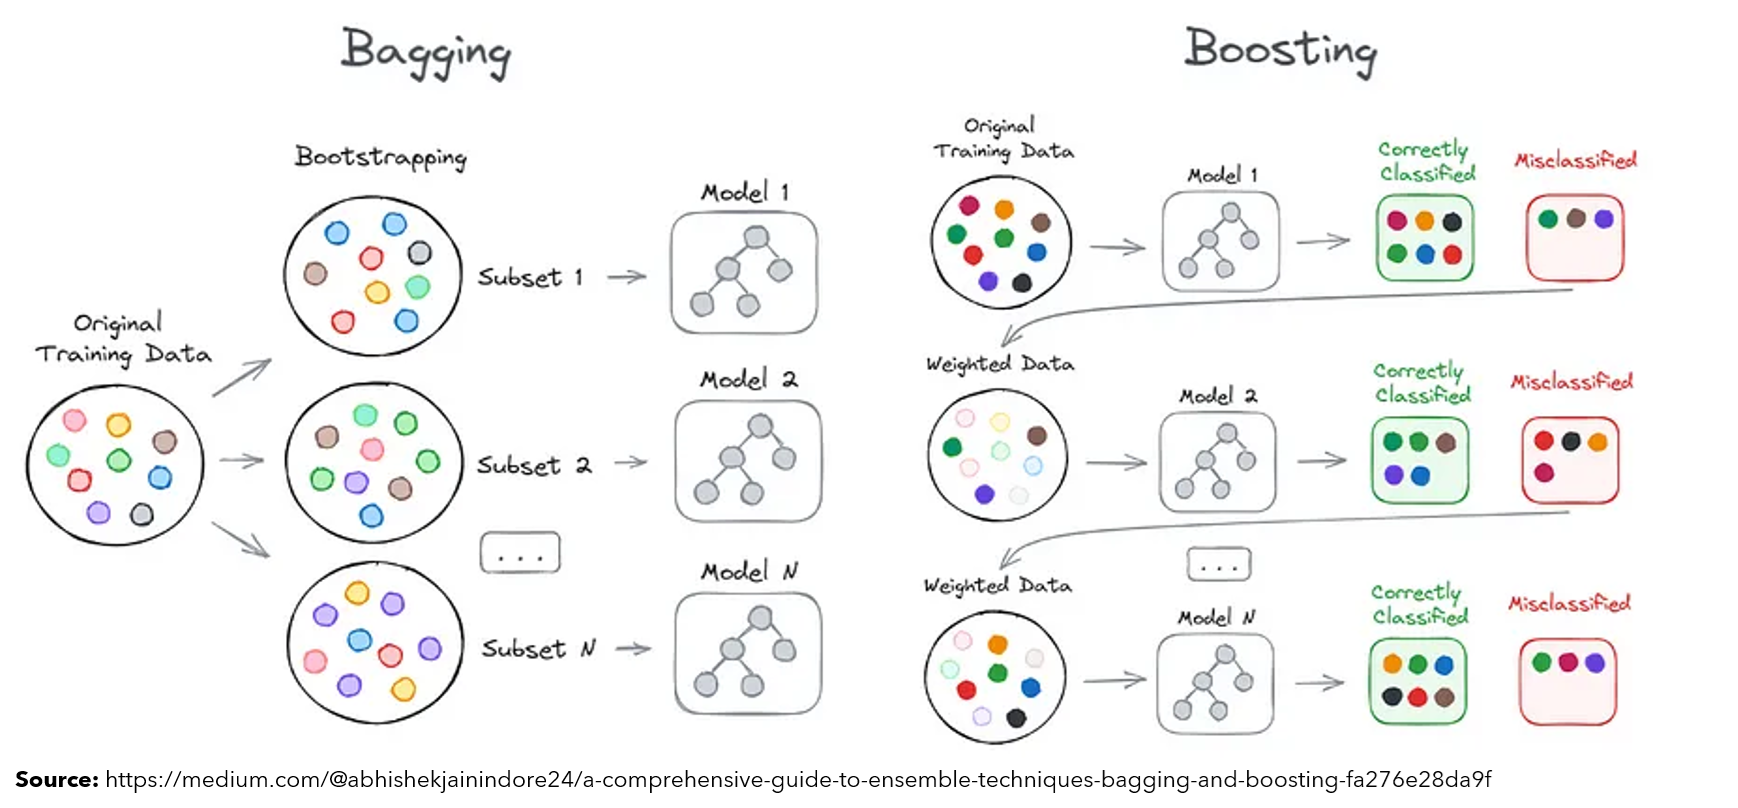

### Step 7.1 — The idea in one figure
📖 Top: the recipe. Bottom: the same recipe on a toy curve (a noisy sine wave) with one-split trees. After one tree the model is a single step; after 100 it follows the curve.

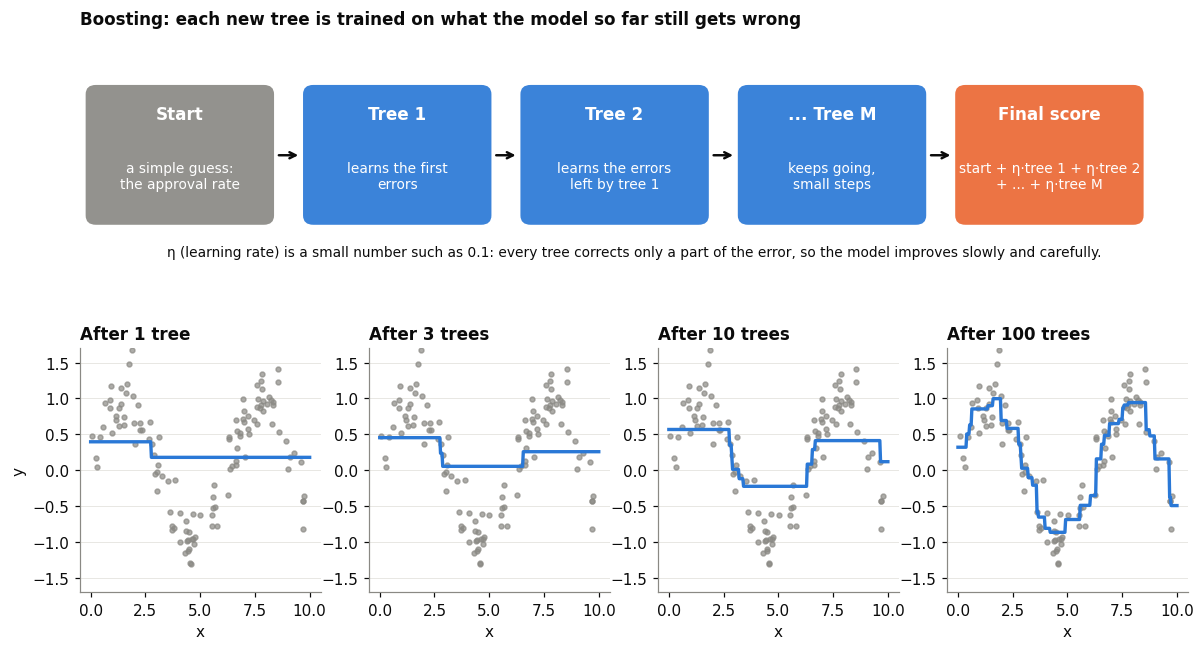

In [29]:
# --- Toy data: a wavy curve with noise, so that we can SEE what each new tree adds ----------------------
rng = np.random.default_rng(SEED)
xs = np.sort(rng.uniform(0, 10, 120)); ys = np.sin(xs) + rng.normal(0, 0.25, 120)
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.3, max_depth=1, random_state=SEED).fit(xs.reshape(-1, 1), ys)
grid_x = np.linspace(0, 10, 300).reshape(-1, 1)
stages = {1: None, 3: None, 10: None, 100: None}
for k, pred in enumerate(gbr.staged_predict(grid_x), start=1):
    if k in stages: stages[k] = pred

fig = plt.figure(figsize=(13, 6.6))
gs = fig.add_gridspec(2, 4, height_ratios=[0.95, 1], hspace=0.35)

# --- Top: the idea in five boxes ---------------------------------------------------------------------------
ax = fig.add_subplot(gs[0, :]); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 3); ax.grid(False)
ax.set_title("Boosting: each new tree is trained on what the model so far still gets wrong")
boxes = [("Start", "a simple guess:\nthe approval rate", GRAY), ("Tree 1", "learns the first\nerrors", BLUE),
         ("Tree 2", "learns the errors\nleft by tree 1", BLUE), ("... Tree M", "keeps going,\nsmall steps", BLUE),
         ("Final score", "start + η·tree 1 + η·tree 2\n+ ... + η·tree M", ORANGE)]
x0 = 0.1
for i, (head, body, col) in enumerate(boxes):
    ax.add_patch(FancyBboxPatch((x0 + i * 2.55, 0.55), 2.15, 1.75, boxstyle="round,pad=0.03,rounding_size=0.12", fc=col, ec="none", alpha=0.92))
    ax.text(x0 + i * 2.55 + 1.075, 1.95, head, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    ax.text(x0 + i * 2.55 + 1.075, 1.15, body, ha="center", va="center", color="white", fontsize=9)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(x0 + (i + 1) * 2.55 - 0.05, 1.42), xytext=(x0 + i * 2.55 + 2.2, 1.42), arrowprops=dict(arrowstyle="->", color=INK, lw=1.6))
ax.text(6.5, 0.12, "η (learning rate) is a small number such as 0.1: every tree corrects only a part of the error, so the model improves slowly and carefully.",
        ha="center", fontsize=9, color=INK)

# --- Bottom: the same idea on a curve --------------------------------------------------------------------
for j, (k, pred) in enumerate(stages.items()):
    a = fig.add_subplot(gs[1, j])
    a.scatter(xs, ys, s=10, color=GRAY, alpha=0.7)
    a.plot(grid_x, pred, color=BLUE, lw=2.2)
    a.set_title(f"After {k} tree{'s' if k > 1 else ''}"); a.set_xlabel("x"); a.set_ylim(-1.7, 1.7); a.grid(axis="x", visible=False)
    if j == 0: a.set_ylabel("y")
plt.show()

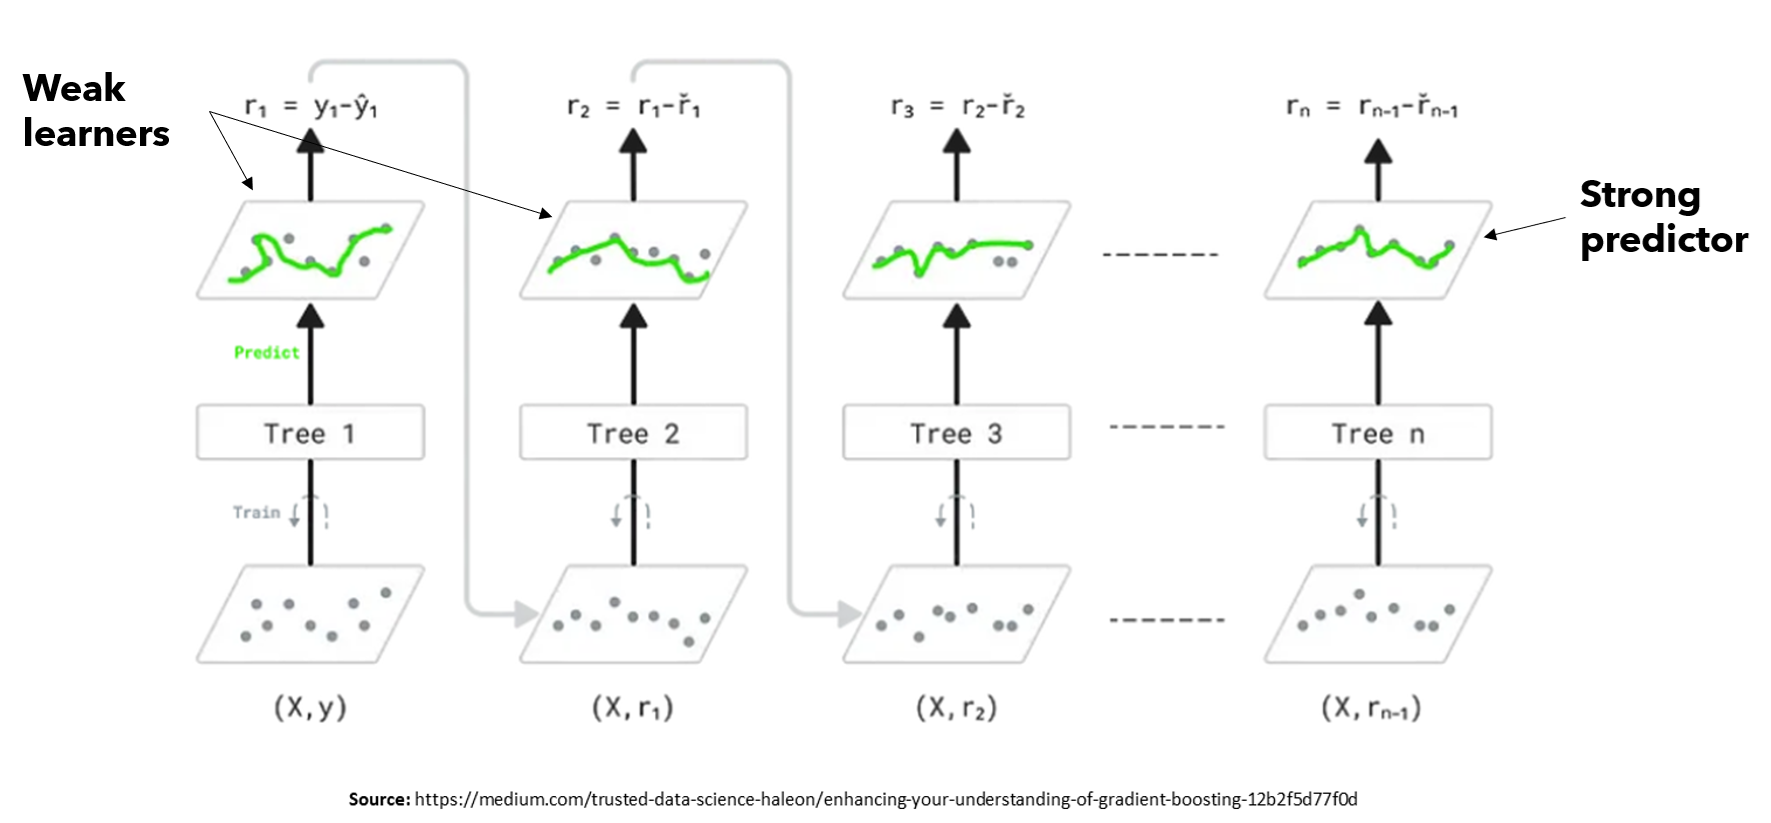

🔍 **What to notice:**
- Each box adds a small correction, scaled by the **learning rate η**: no tree is trusted fully, which is what makes boosting slow, careful and hard to overfit with the right settings.
- The bottom panels show the model improving from a flat step to a close fit of the wave, one small tree at a time. Compare with a forest: a forest averages 50 *independent*, deep trees; boosting adds 100 *dependent*, shallow ones.

| | Bagging / Random Forest | Boosting |
|---|---|---|
| Trees built | independently, in parallel | sequentially, each on the previous errors |
| Trees are | deep (low bias, high variance) | shallow (high bias, low variance) |
| Main effect | reduces variance | reduces bias |
| Sensitive to noise and outliers | little | more, since it keeps chasing errors |

### Step 7.2 — Boosting by hand on the credit data
📖 Start from the approval rate. Round after round: compute the **errors** (actual − current probability), fit a small depth-2 tree to those errors, and add a fraction η of it to the model.

       mean |error| (train)  train AUC  test AUC
trees                                           
0                     0.485      0.500     0.500
1                     0.471      0.823     0.789
2                     0.458      0.828     0.798
3                     0.447      0.850     0.827
4                     0.436      0.865     0.852
5                     0.426      0.866     0.852
6                     0.416      0.866     0.852
7                     0.408      0.870     0.856
8                     0.400      0.870     0.859

scikit-learn with the same settings: test AUC 0.904 (our simplified version: 0.859; scikit-learn also refines each leaf value, so the two are close in spirit, not identical)


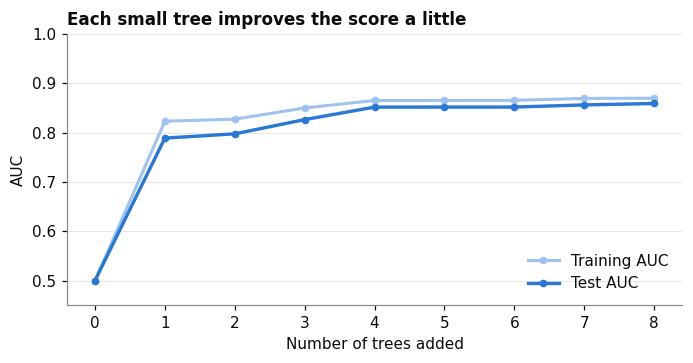

In [30]:
eta, rounds = 0.3, 8                                     # learning rate and number of small trees
p0 = y_train.mean()
F_tr = np.full(len(y_train), np.log(p0 / (1 - p0)))        # start: the log-odds of the approval rate
F_te = np.full(len(y_test),  np.log(p0 / (1 - p0)))
sigmoid = lambda f: 1 / (1 + np.exp(-f))

rows = [{"trees": 0, "mean |error| (train)": np.abs(y_train - sigmoid(F_tr)).mean(),
         "train AUC": 0.5, "test AUC": 0.5}]
for m in range(1, rounds + 1):
    resid = y_train - sigmoid(F_tr)                         # what the model still gets wrong
    tree_m = DecisionTreeRegressor(max_depth=2, random_state=SEED).fit(X_train, resid)   # a small tree learns those errors
    F_tr = F_tr + eta * tree_m.predict(X_train)             # add a small step of the new tree
    F_te = F_te + eta * tree_m.predict(X_test)
    rows.append({"trees": m, "mean |error| (train)": np.abs(y_train - sigmoid(F_tr)).mean(),
                 "train AUC": roc_auc_score(y_train, F_tr), "test AUC": roc_auc_score(y_test, F_te)})
hand = pd.DataFrame(rows).set_index("trees")
print(hand.round(3).to_string())

check = GradientBoostingClassifier(n_estimators=rounds, learning_rate=eta, max_depth=2, random_state=SEED).fit(X_train, y_train)
print(f"\nscikit-learn with the same settings: test AUC {roc_auc_score(y_test, check.predict_proba(X_test)[:, 1]):.3f} (our simplified version: {hand.loc[rounds, 'test AUC']:.3f}; scikit-learn also refines each leaf value, so the two are close in spirit, not identical)")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(hand.index, hand["train AUC"], color=LIGHT_BLUE, lw=2, marker="o", ms=4, label="Training AUC")
ax.plot(hand.index, hand["test AUC"], color=BLUE, lw=2.2, marker="o", ms=4, label="Test AUC")
ax.set_xlabel("Number of trees added"); ax.set_ylabel("AUC"); ax.set_ylim(0.45, 1.0); ax.set_title("Each small tree improves the score a little")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

🔍 **What to notice:** the average training error falls from **0.485** to **0.400** in 8 rounds, and the test AUC rises from **0.789** (one tree, the same as the Week 5 tree) to **0.859**. Each small tree helps a little. Our simplified version is not identical to `scikit-learn` (**0.904** with the same settings) because the library also adjusts each leaf value; the principle is the same.

### Step 7.3 — Tune it: cross-validate the settings
📖 Four levers matter: **number of trees**, **learning rate** (smaller = slower, needs more trees), **tree depth** (usually 1–4) and **subsample** (the share of rows each tree sees; below 1 it is "stochastic" boosting and adds a little randomness). We search a grid with the **same 10 folds** and, for each setting, read the best number of trees from one fit per fold.

In [31]:
N_TREES = 400                                            # we grow up to 400 trees and look at every size on the way
STEP = 5                                                  # score the validation fold every 5 trees
sizes = np.arange(STEP, N_TREES + 1, STEP)

def staged_cv(lr_, depth, sub):
    """10-fold CV of one setting: validation AUC after 5, 10, ..., 400 trees (one fit per fold gives all sizes)."""
    out = np.zeros((10, len(sizes)))
    for k, (i_tr, i_va) in enumerate(skf.split(X_train, y_train)):
        m = GradientBoostingClassifier(n_estimators=N_TREES, learning_rate=lr_, max_depth=depth, subsample=sub,
                                       random_state=SEED).fit(X_train.iloc[i_tr], y_train.iloc[i_tr])
        yv = y_train.iloc[i_va]
        for j, p_ in enumerate(m.staged_predict_proba(X_train.iloc[i_va])):
            if (j + 1) % STEP == 0:
                out[k, (j + 1) // STEP - 1] = roc_auc_score(yv, p_[:, 1])
    return out

settings = [(lr_, d, s) for lr_ in (0.02, 0.05, 0.1, 0.2) for d in (1, 2, 3, 4) for s in (0.6, 1.0)]
print(f"Trying {len(settings)} settings x 10 folds (about 3-5 minutes)...")
t0 = time.perf_counter()
cv_gb = Parallel(n_jobs=-1)(delayed(staged_cv)(*s) for s in settings)
print(f"Done in {time.perf_counter() - t0:.0f} s")

rows = []
for (lr_, d, s), arr in zip(settings, cv_gb):
    mean = arr.mean(axis=0); j = int(mean.argmax())
    rows.append({"learning_rate": lr_, "max_depth": d, "subsample": s, "best n_estimators": int(sizes[j]),
                 "CV AUC": mean[j], "se": arr[:, j].std(ddof=1) / np.sqrt(10)})
gb_tbl = pd.DataFrame(rows).sort_values("CV AUC", ascending=False).reset_index(drop=True)
print("\nThe 8 best settings:"); print(gb_tbl.head(8).round(3).to_string())

best = gb_tbl.iloc[0]
gb_params = dict(n_estimators=int(best["best n_estimators"]), learning_rate=float(best["learning_rate"]),
                 max_depth=int(best["max_depth"]), subsample=float(best["subsample"]), random_state=SEED)
print("\nOptimal gradient boosting:", gb_params)

Trying 32 settings x 10 folds (about 3-5 minutes)...
Done in 192 s

The 8 best settings:
   learning_rate  max_depth  subsample  best n_estimators  CV AUC     se
0           0.20          2        0.6                 95   0.896  0.017
1           0.20          3        0.6                 20   0.894  0.014
2           0.02          4        0.6                155   0.893  0.016
3           0.10          2        0.6                 95   0.892  0.017
4           0.05          3        0.6                230   0.892  0.017
5           0.02          3        0.6                175   0.891  0.015
6           0.02          2        0.6                365   0.890  0.017
7           0.10          3        0.6                100   0.890  0.016

Optimal gradient boosting: {'n_estimators': 95, 'learning_rate': 0.2, 'max_depth': 2, 'subsample': 0.6, 'random_state': 42}


🔍 **What to notice:** the best setting is a learning rate of **0.2**, depth **2**, subsample **0.6** and **95 trees**, with a CV AUC of **0.896** (standard error 0.017). The 8 best settings are all between 0.891 and 0.896, so this is again a plateau, not a sharp optimum. All of them use `subsample = 0.6`, so showing each tree only 60% of the rows helped consistently. A small learning rate (0.02) needs more trees (365) for the same score.

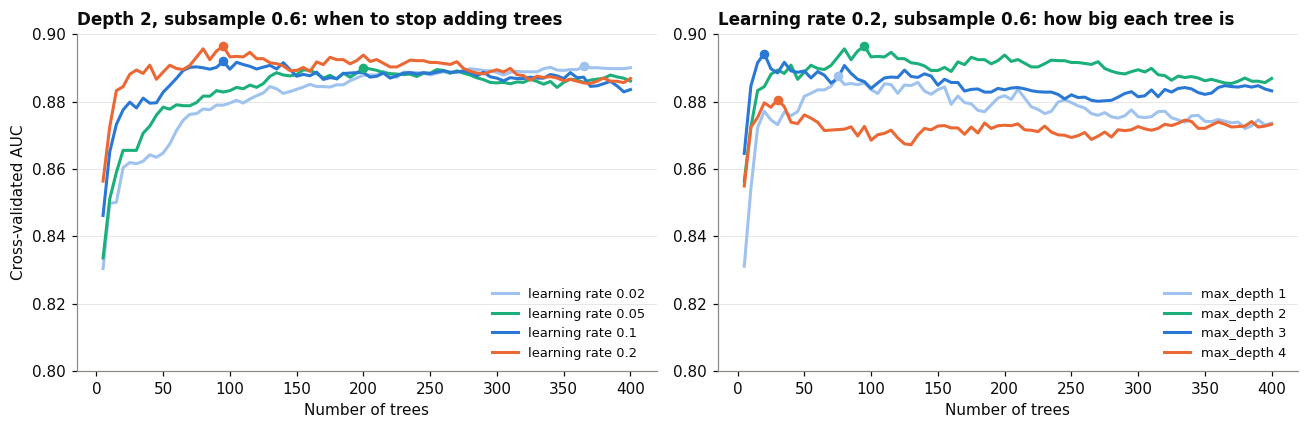

In [32]:
# Validation AUC against the number of trees, for the best depth and subsample, one line per learning rate
d_b, s_b = int(best["max_depth"]), float(best["subsample"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for lr_, col in zip((0.02, 0.05, 0.1, 0.2), [LIGHT_BLUE, AQUA, BLUE, ORANGE]):
    arr = cv_gb[settings.index((lr_, d_b, s_b))].mean(axis=0)
    ax.plot(sizes, arr, color=col, lw=2, label=f"learning rate {lr_}")
    ax.scatter(sizes[arr.argmax()], arr.max(), color=col, s=28, zorder=3)
ax.set_xlabel("Number of trees"); ax.set_ylabel("Cross-validated AUC"); ax.set_title(f"Depth {d_b}, subsample {s_b}: when to stop adding trees")
ax.legend(frameon=False, loc="lower right", fontsize=8.5); ax.grid(axis="x", visible=False)

ax = axes[1]
for d_, col in zip((1, 2, 3, 4), [LIGHT_BLUE, AQUA, BLUE, ORANGE]):
    arr = cv_gb[settings.index((float(best["learning_rate"]), d_, s_b))].mean(axis=0)
    ax.plot(sizes, arr, color=col, lw=2, label=f"max_depth {d_}")
    ax.scatter(sizes[arr.argmax()], arr.max(), color=col, s=28, zorder=3)
ax.set_xlabel("Number of trees"); ax.set_title(f"Learning rate {best['learning_rate']}, subsample {s_b}: how big each tree is")
ax.legend(frameon=False, loc="lower right", fontsize=8.5); ax.grid(axis="x", visible=False)
for a in axes: a.set_ylim(0.80, 0.90)
plt.tight_layout(); plt.show()

🔍 **What to notice:** every curve **rises quickly, peaks and then drifts down**: past the best number of trees, extra trees only memorize noise. With a high learning rate (orange, left) the peak comes early (about 100 trees) and the drop is steeper; with a low one it comes later and flatter. On the right, depth 1–2 beats depth 4: **small trees** are what boosting wants. The dots mark the best number of trees for each curve.

> 💡 **Tip.** In boosting, the number of trees is a tuning knob, not "the more the better" as in a forest. Choose it by cross-validation (or early stopping).

### Step 7.4 — Fit the optimal gradient boosting and evaluate it
📖 We refit with the best setting on the whole training set and score the test set once.

In [33]:
gb_model = GradientBoostingClassifier(**gb_params)
b = score_model("Gradient boosting", gb_model)
print(cv_line("Gradient boosting"))
print({k: (int(v) if k in ("TN", "FP", "FN", "TP") else round(v, 3)) for k, v in b["test"].items()})
print(f"Training accuracy {b['train']['Accuracy']:.3f} | test accuracy {b['test']['Accuracy']:.3f} | gap {b['train']['Accuracy'] - b['test']['Accuracy']:.3f} "
      f"-> {diagnose(b['train']['Accuracy'], b['test']['Accuracy'], base_train)}")

Gradient boosting: CV AUC 0.896 (standard error 0.017) | CV accuracy 0.828
{'TN': 76, 'FP': 5, 'FN': 20, 'TP': 37, 'Accuracy': 0.819, 'Precision': 0.881, 'Recall': 0.649, 'F1': 0.747}
Training accuracy 0.922 | test accuracy 0.819 | gap 0.103 -> OVERFITTING


🔍 **What to notice:** CV AUC **0.896** and CV accuracy **0.828**. On the test set: accuracy **0.812**, precision **0.860**, recall **0.649**, F1 **0.740** (75 TN, 6 FP, 20 FN, 37 TP). As with the forest, the training-test accuracy gap (0.933 − 0.812 = 0.121) is flagged by the rule of thumb; the CV and test scores are the ones to read.

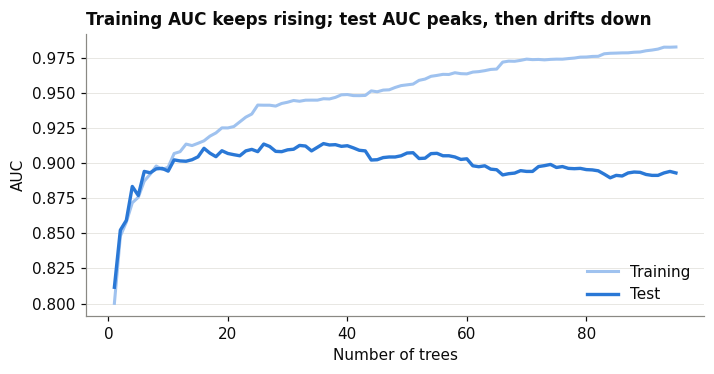

After 95 trees: training AUC 0.983 | test AUC 0.893


In [34]:
# What if we keep adding trees? Training vs test AUC of the optimal setting, tree after tree
tr_auc = [roc_auc_score(y_train, p_[:, 1]) for p_ in gb_model.staged_predict_proba(X_train)]
te_auc = [roc_auc_score(y_test,  p_[:, 1]) for p_ in gb_model.staged_predict_proba(X_test)]
fig, ax = plt.subplots(figsize=(6.6, 3.5))
ax.plot(range(1, len(tr_auc) + 1), tr_auc, color=LIGHT_BLUE, lw=2, label="Training")
ax.plot(range(1, len(te_auc) + 1), te_auc, color=BLUE, lw=2.2, label="Test")
ax.set_xlabel("Number of trees"); ax.set_ylabel("AUC"); ax.set_title("Training AUC keeps rising; test AUC peaks, then drifts down")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()
print(f"After {len(tr_auc)} trees: training AUC {tr_auc[-1]:.3f} | test AUC {te_auc[-1]:.3f}")

🔍 **What to notice:** with our chosen 95 trees the training AUC is **0.982** and the test AUC **0.891**. The test AUC actually peaks at about 0.91 near 35 trees and then drifts down while the training AUC keeps rising: the signature of boosting that runs too long. Cross-validation (Step 7.3) is flat between about 35 and 100 trees, so 95 is within the plateau, but this is a reminder that **more trees is not better** in boosting, and that a smaller number of trees would be a defensible choice.

### Step 7.5 — Logistic regression vs Random Forest vs Gradient boosting
📖 The same scoreboard, same test set, same threshold. The gains of one model over another are measured over the same folds.

                     CV AUC  Accuracy  Precision  Recall     F1  Test AUC  Train acc. - test acc.  Fit time (s)
Model                                                                                                          
Logistic regression   0.876     0.826      0.902   0.649  0.755     0.897                  -0.006         0.015
Random Forest         0.881     0.812      0.897   0.614  0.729     0.897                   0.121         0.070
Gradient boosting     0.896     0.819      0.881   0.649  0.747     0.893                   0.103         0.109

Baseline accuracy (always 'denied'): 0.587 | Week 5 tree: CV AUC 0.790, test AUC 0.789
Paired CV AUC difference, Gradient boosting minus Logistic regression: +0.021 (standard error 0.011)
Paired CV AUC difference, Gradient boosting minus Random Forest: +0.015 (standard error 0.007)


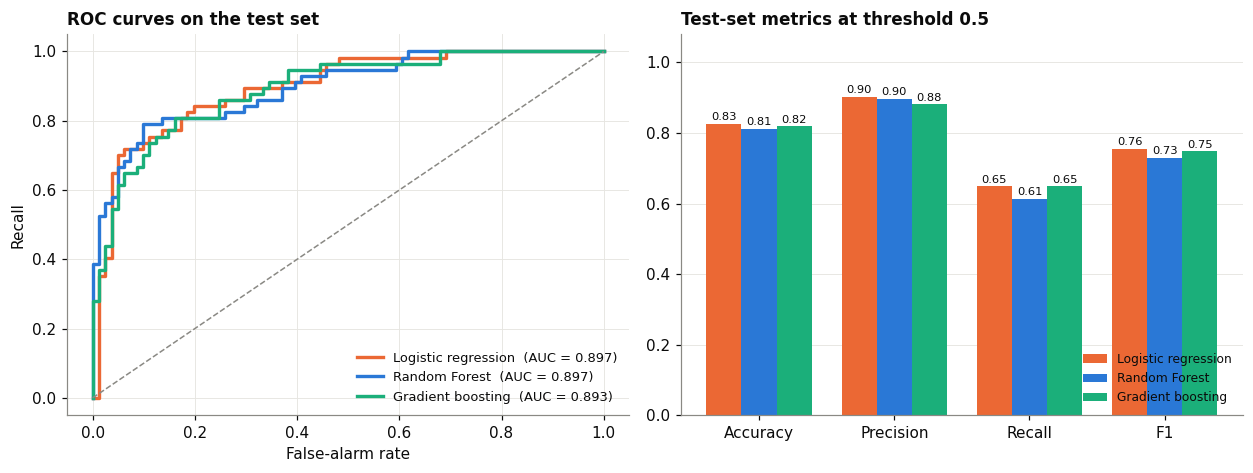

In [35]:
order = ["Logistic regression", "Random Forest", "Gradient boosting"]
rows = []
for nme in order:
    b = board[nme]
    rows.append({"Model": nme, "CV AUC": b["cv_auc"].mean(), "Accuracy": b["test"]["Accuracy"], "Precision": b["test"]["Precision"],
                 "Recall": b["test"]["Recall"], "F1": b["test"]["F1"], "Test AUC": b["auc_test"],
                 "Train acc. - test acc.": b["train"]["Accuracy"] - b["test"]["Accuracy"], "Fit time (s)": b["fit_s"]})
cmp3 = pd.DataFrame(rows).set_index("Model")
print(cmp3.round(3).to_string())
print(f"\nBaseline accuracy (always 'denied'): {baseline_test:.3f} | Week 5 tree: CV AUC {board['Single tree (Week 5)']['cv_auc'].mean():.3f}, "
      f"test AUC {board['Single tree (Week 5)']['auc_test']:.3f}")

for a_, b_ in [("Logistic regression", "Gradient boosting"), ("Random Forest", "Gradient boosting")]:
    d_ = board[b_]["cv_auc"] - board[a_]["cv_auc"]
    print(f"Paired CV AUC difference, {b_} minus {a_}: {d_.mean():+.3f} (standard error {d_.std(ddof=1) / np.sqrt(len(d_)):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
for name, col in zip(order, [ORANGE, BLUE, AQUA]):
    fpr, tpr, _ = roc_curve(y_test, board[name]["p_test"])
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f"{name}  (AUC = {board[name]['auc_test']:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
ax.set_xlabel("False-alarm rate"); ax.set_ylabel("Recall"); ax.set_title("ROC curves on the test set")
ax.legend(frameon=False, loc="lower right", fontsize=8.5); ax.grid(axis="x", visible=True)

ax = axes[1]
w = 0.26
for k, (metric, lab) in enumerate([("Accuracy", "Accuracy"), ("Precision", "Precision"), ("Recall", "Recall"), ("F1", "F1")]):
    for i, (name, col) in enumerate(zip(order, [ORANGE, BLUE, AQUA])):
        v = board[name]["test"][metric]
        ax.bar(k + (i - 1) * w, v, width=w, color=col, label=name if k == 0 else None)
        ax.text(k + (i - 1) * w, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(range(4)); ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1"]); ax.set_ylim(0, 1.08)
ax.set_title("Test-set metrics at threshold 0.5"); ax.legend(frameon=False, loc="lower right", fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

🔍 **What to notice:**
- **Cross-validation** puts gradient boosting first: CV AUC **0.896**, against 0.881 (forest) and 0.876 (logistic regression). The paired gains are +0.015 (standard error 0.007) over the forest and +0.020 (standard error 0.011) over the regression.
- On the **test set** the story changes: boosting has the lowest test AUC (**0.891** against 0.897 for the other two) and the lowest precision (0.860). Its accuracy (0.812) and F1 (0.740) are the same as the forest's and below the regression's (0.826 and 0.755).
- All three are clearly better than the Week 5 tree (CV AUC 0.790, test AUC 0.789), and all three fit and score in a fraction of a second here.

In [36]:
for a_, b_ in [("Logistic regression", "Gradient boosting"), ("Random Forest", "Gradient boosting")]:
    d_ = board[b_]["cv_auc"] - board[a_]["cv_auc"]
    z_ = d_.mean() / (d_.std(ddof=1) / np.sqrt(len(d_)))
    print(f"{b_} vs {a_}: {pick_winner(a_, b_)[1]}")
    print(f"   the paired gain is {z_:.1f} standard errors")
print("\nTest AUC:", {k: round(board[k]["auc_test"], 3) for k in order})

Gradient boosting vs Logistic regression: Gradient boosting minus Logistic regression = +0.021 CV AUC, larger than 1 SE (0.011): the higher model is ahead in cross-validation
   the paired gain is 1.9 standard errors
Gradient boosting vs Random Forest: Gradient boosting minus Random Forest = +0.015 CV AUC, larger than 1 SE (0.007): the higher model is ahead in cross-validation
   the paired gain is 2.2 standard errors

Test AUC: {'Logistic regression': np.float64(0.897), 'Random Forest': np.float64(0.897), 'Gradient boosting': np.float64(0.893)}


🔍 **What to notice:** by our one-standard-error rule, gradient boosting is **ahead in cross-validation**, by about 2 standard errors over both other models. But that is the *tuned* boosting (we searched 32 settings and kept the best), compared with a forest that was not tuned, which gives it a head start, and the **test set does not confirm** the gain.

**Where does that leave the decision?** The criteria are the ones of Section 5:
- **Predictive quality:** boosting is slightly ahead in cross-validation, but not on the test set, so the evidence is weak.
- **Explainability under ECOA:** worst of the three (hundreds of small trees chained together).
- **Risk:** more sensitive to noisy data and outliers, with more settings to monitor.

So the **recommendation stays with the logistic regression** as the production model, with boosting as the **challenger** to re-test on more data. If the bank later accepts an explanation layer (for example reason codes computed from a boosted model) the case for boosting would be stronger.

### Step 7.6 — All four models on the 20 new applicants
📖 The same 20 applicants, scored by each model on the scoreboard with the 0.5 threshold.

In [37]:
rows = []
for nme in ["Single tree (Week 5)", "Logistic regression", "Random Forest", "Gradient boosting"]:
    bm = board[nme]
    pn = bm["model"].predict_proba(new[bm["cols"]])[:, 1]
    mn = metrics_at(actual_new.reindex(new.index), pn, THR)
    rows.append({"Model": nme, "Approved at 0.5": int((pn >= THR).sum()), "Correct (of 20)": mn["TN"] + mn["TP"],
                 "Accuracy": mn["Accuracy"], "Precision": mn["Precision"], "Recall": mn["Recall"], "F1": mn["F1"],
                 "AUC": roc_auc_score(actual_new.reindex(new.index), pn)})
tbl20 = pd.DataFrame(rows).set_index("Model")
print(tbl20.round(2).to_string())
print(f"\nBaseline 'deny everybody': {1 - actual_new.mean():.2f} | the actual decisions approved {int(actual_new.sum())} of 20")

                      Approved at 0.5  Correct (of 20)  Accuracy  Precision  Recall    F1   AUC
Model                                                                                          
Single tree (Week 5)                5               15      0.75       0.80    0.50  0.62  0.90
Logistic regression                 6               16      0.80       0.83    0.62  0.71  0.93
Random Forest                       8               16      0.80       0.75    0.75  0.75  0.90
Gradient boosting                   7               15      0.75       0.71    0.62  0.67  0.86

Baseline 'deny everybody': 0.60 | the actual decisions approved 8 of 20


🔍 **What to notice:** the number of correct decisions is **15** (tree), **16** (logistic regression), **16** (forest) and **14** (boosting), against 12 for "deny everybody"; and 8 of the 20 were really approved. The models approve 5, 6, 8 and 10 applicants: the more recall-oriented a model is, the more approvals it makes and the more risky ones it lets in. The AUCs on these 20 are 0.90, 0.93, 0.90 and 0.86. With 20 applicants, a one-applicant difference is 5 points, so this table cannot rank the models; it just shows they all work.

### Step 7.7 — Advantages and risks of boosting
**Advantages**
- **High accuracy** on tabular data: with careful tuning, boosted trees are often the best model in practice.
- **Reduces bias:** it can fit patterns that shallow trees and straight lines miss, by adding small corrections.
- **Flexible:** it works with different loss functions, mixed predictors and interactions without standardizing, and it gives variable importance.
- **Small trees, small memory per tree:** each tree is 2 levels here; the model is an ensemble of simple pieces.

**Risks and costs**
- **Overfits noise and outliers** if it runs too long or too aggressively, because every tree chases what is still wrong. The number of trees must be tuned (Step 7.3).
- **More settings to tune** (trees, learning rate, depth, subsample) and a **sequential** training that cannot be parallelized across trees as in a forest.
- **Hard to explain**, which matters in regulated decisions like credit.

> 📌 **Heads up.** Faster implementations of the same idea exist (XGBoost, LightGBM, CatBoost, `HistGradientBoostingClassifier` in scikit-learn); the levers and the logic are the ones you just practiced.

## Quick reference and practice

### Recipes you can reuse
| Goal | Code recipe |
|---|---|
| Bootstrap sample of the rows | `idx = rng.integers(0, n, n)` then `X.iloc[idx]` |
| Share of distinct rows in a bootstrap sample | `1 - (1 - 1/n)**n` (about 63.2%) |
| Random Forest | `RandomForestClassifier(n_estimators=50, max_depth=12, min_samples_split=10, min_samples_leaf=1, max_features="sqrt", criterion="gini", random_state=0, class_weight=None)` |
| Out-of-bag score | `RandomForestClassifier(..., oob_score=True).fit(X, y).oob_score_` |
| OOB probabilities | `forest.oob_decision_function_[:, 1]` |
| Cross-validated AUC | `cross_validate(model, X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"])` |
| One lever at a time | `sweep("max_depth", [1, 2, 4, 8, None])` (Step 2.3) |
| Importance (impurity) | `forest.feature_importances_` |
| Importance (permutation) | `permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=30)` |
| Unregularized logistic regression | `make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))` |
| Odds ratio per 1 SD | `np.exp(model[-1].coef_[0])` |
| Metrics at a threshold | `metrics_at(y, p, thr)` (Step 0.2) |
| ROC and AUC | `roc_curve(y, p)`, `roc_auc_score(y, p)` |
| Gradient boosting | `GradientBoostingClassifier(n_estimators=95, learning_rate=0.2, max_depth=2, subsample=0.6)` |
| Probability after each tree | `for p in gb.staged_predict_proba(X): ...` |
| Paired comparison of two models | difference of the 10 fold scores; mean / standard error (Step 5.3) |

### Practice
Try these on your own before opening the solution cell.
1. What share of the applicants is in a bootstrap sample of 551 draws? What does the rest become?
2. What is the 10-fold CV AUC of the course configuration with **300** trees? Compare it with 50 trees.
3. How many predictors does each split consider with the square-root rule? What is the CV AUC if every split may use **all** the predictors (bagging)? Is the difference important?
4. How many predictors does the logistic regression use, and what is the odds ratio of `CreditScore` per standard deviation?
5. Fit gradient boosting with 50 and with 400 trees (learning rate 0.1, depth 2). How do the training AUC and the CV AUC change?

In [ ]:
# ---- Solutions ----
# 1. Share of distinct applicants in a bootstrap sample of n = 551
print(f"1. {1 - (1 - 1 / 551) ** 551:.3f}  (about 63%; the rest is out of bag)")

# 2. The course configuration with 300 trees instead of 50
r2 = cross_validate(RandomForestClassifier(**{**rf_params, "n_estimators": 300}), X_train, y_train, cv=skf, scoring="roc_auc", n_jobs=-1)
print(f"2. 300 trees: CV AUC {r2['test_score'].mean():.3f}  |  50 trees: {board['Random Forest']['cv_auc'].mean():.3f}")

# 3. Bagging: let every split use all predictors
r3 = cross_validate(RandomForestClassifier(**{**rf_params, "max_features": None}), X_train, y_train, cv=skf, scoring="roc_auc", n_jobs=-1)
print(f"3. m = {int(np.sqrt(len(PRED)))} predictors per split with the square-root rule; bagging (all {len(PRED)}): CV AUC {r3['test_score'].mean():.3f}")

# 4. Odds ratio of CreditScore in the logistic regression
print(f"4. {len(LR_COLS)} predictors; odds ratio of CreditScore per 1 SD = {np.exp(coef['CreditScore']):.2f}")

# 5. Gradient boosting: 50 trees vs 400 trees at learning rate 0.1, depth 2
for n_ in (50, 400):
    r5 = cross_validate(GradientBoostingClassifier(n_estimators=n_, learning_rate=0.1, max_depth=2, random_state=SEED),
                        X_train, y_train, cv=skf, scoring="roc_auc", return_train_score=True, n_jobs=-1)
    print(f"5. {n_} trees: train AUC {r5['train_score'].mean():.3f} | CV AUC {r5['test_score'].mean():.3f}")

🔍 **What to notice:** (1) about 63.2%; the rest is out of bag. (2) 300 trees give 0.891 against 0.881, a small gain that is within the noise. (3) Three predictors per split; bagging gives 0.885, about the same as the forest's 0.881: on this dataset the difference is inside the noise (see the note in Step 3.5). (4) Nine predictors and an odds ratio of 4.59. (5) With 400 trees the training AUC climbs from 0.939 to 0.997, but the CV AUC barely moves (0.878 to 0.880): more trees memorize, they do not generalize.

## Wrap-up — Key ideas
- A single tree has **high variance**: bootstrap resamples of the same data gave trees with test AUC from 0.74 to 0.85.
- **Bagging** trains trees on **bootstrap samples** (same size, with replacement): about 63% of the applicants are in each sample and the other 37% are **out of bag**, which gives a free validation score.
- A **Random Forest** adds a second layer of randomness: each split looks at only **√p** predictors (3 of 10). This makes trees less correlated, and averaging less correlated trees reduces variance more.
- A forest wants **deep trees**: its CV AUC did not fall with depth and plateaued after 100–200 trees. Its training score is always inflated, so judge it with **OOB, cross-validation and test**.
- With the course configuration (50 trees, depth 12, min split 10, √p predictors) the forest reached CV AUC **0.881** and test AUC **0.897**, against 0.790 and 0.789 for the Week 5 tree.
- The **unregularized logistic regression** (standardized predictors, `C=np.inf`) reached CV AUC **0.876** and test AUC **0.897**: a statistical **tie** (paired difference 0.005 with standard error 0.007).
- When performance ties, the **other criteria decide**: the logistic regression is explainable, stable and cheap, so it is the selected model for a lender that must give reasons. It decided 16 of 20 new applicants correctly (the tree: 15).
- **Gradient boosting** builds small trees **one after another**, each on the errors left by the previous ones, controlled by a **learning rate**; it reduces **bias**. Tuned (rate 0.2, depth 2, subsample 0.6, 95 trees) it led in cross-validation (0.896) but **not** on the test set (0.891), and it is the hardest to explain.
- **Advantages of boosting:** top accuracy on tabular data, flexibility, no standardizing. **Risks:** overfits noise and outliers, many settings, sequential and hard to explain.
- The models differ by tiny amounts relative to the noise of 138 test applicants and 20 new ones: **measure the noise** (paired folds, bootstrap) before declaring a winner.

*End of the Week 6 lab.*